# Detecting troll tweets about Catalan independence

*Final project: Text Mining, Barcelona School of Economics (BGSE)*

## Question

Twitter published the tweets of accounts it suspended for platform manipulation around Catalan politics (its Information Operations archive, `catalonia_201906_1`, released June 2019). **Can these "troll" tweets be told apart from ordinary Spanish-language tweets on the same topics, using their text, writing style and account metadata?**

## Data (not included in this repository)

| File | Contents | Rows used |
|---|---|---|
| `catalonia_201906_1_tweets_csv_hashed.csv` | Troll tweets, 2017–2018, from Twitter's Information Operations archive | 9,489 |
| `es_tweets_2017_2019_16k_v2.csv` | Random Spanish-language tweets, 2017–2019 (control group) | 389,734 after the topic filter |

## Pipeline

1. **Cleaning:** remove mentions, links, stop words (English / Spanish / Catalan lists from `stopwordsiso` plus custom lists), hashtags, emojis, Twitter abbreviations, symbols and long garbage strings.
2. **Feature engineering:**
   * *tweet level:* length, number of mentions / hashtags / abbreviations / stop words, ratio of capital letters, retweet-or-reply flag;
   * *account level:* digits in the display name, follower/following ratio, account age, client app, posting date and time.
3. **Exploratory analysis:** token frequencies (yellowbrick), K-means + t-SNE clusters, time between tweets, and troll vs random distributions of every feature.
4. **Comparable control group:** keep only random tweets that mention Catalan-politics keywords.
5. **Models:**
   * *text only:* language detection (`langdetect`), Spanish Snowball stemming, TF-IDF, SMOTE oversampling, logistic regression;
   * *account + tweet statistics:* target encoding of categorical features, standard scaling, SMOTE, logistic regression.

**Tools:** pandas, NumPy, regex, NLTK, stopwordsiso, langdetect, scikit-learn, imbalanced-learn (SMOTE), category_encoders, yellowbrick, matplotlib, seaborn, Google Colab.

## Key findings

* **Posting hours:** trolls tweet mostly during office hours (09:00–15:00), while the control group peaks in the evening.
* **Activity over time:** troll activity peaks in March 2018 and October 2018 (around the first anniversary of the 1 October referendum).
* **Client app:** trolls post mainly through **TweetDeck** (~37%) and the **web client** (~32%); the control group mostly uses the Android and iPhone apps.
* **Display names:** most troll display names contain 3–8 digits, while ~95% of control accounts have none.
* **Not simple bots:** the time between consecutive troll tweets varies widely, which does not fit fixed-schedule bots.

## Results (30% held-out test set)

| Model | Accuracy | Majority-class baseline | Troll precision | Troll recall |
|---|---|---|---|---|
| Text only (TF-IDF + SMOTE + LR, Spanish tweets) | 0.975 | 0.997 | 0.07 | 0.59 |
| Account + tweet statistics (SMOTE + LR) | **0.991** | 0.976 | **0.74** | **0.99** |

Behavioural and account features separate trolls far better than the wording of their tweets. The text-only model scores *below* the "always predict not-troll" baseline and flags many ordinary political tweets as trolls.

## Notes on this revision

The notebook was tidied after the original Colab run: imports deduplicated, unused helpers and dead code removed, file paths centralised in `DATA_DIR`, comments and explanations added. **Every saved output has been kept.** Since the data is not in this repository, cells were only changed in ways that do not alter their results, and known issues are listed below instead of silently "fixed". The only cell rewritten without being re-run is the cross-validated text pipeline, and it is marked.

**Known issues in the saved results**

1. `remove_abbr` removes abbreviations such as *IN*, *LI*, *RT* even *inside* words. That is why tokens like *repúbca* (república), *dependencia* (independencia), *aicle* (article) and *lbeat* (llibertat) appear. Pass `whole_words=True` to fix it.
2. The account model re-fits the `StandardScaler` on the test set (`fit_transform` instead of `transform`).
3. "Train" accuracies are computed on SMOTE-resampled data.
4. `hashtag_count` is `len()` of the raw `hashtags` text, so it counts characters (2 = empty list `[]`) rather than hashtags.
5. Some histograms (follower/following ratio, caps ratio, account age) plot how often each value occurs, not the values themselves.
6. The control group is selected by *substring* keyword matching, which is loose (e.g. *cup* also matches *ocupar*).
7. The two datasets were collected differently, so some strong signals (client app, posting hour) may partly reflect how the data was collected rather than troll behaviour.

# Setup: libraries and Google Drive

In [ ]:
!pip install emojis
!pip install stopwordsiso
!pip install langdetect
!pip install spacy_spanish_lemmatizer


     |████████████████████████████████| 81kB 3.6MB/s 
     |████████████████████████████████| 983kB 6.9MB/s 
  Created wheel for langdetect: filename=langdetect-1.0.9-cp37-none-any.whl size=993242 sha256=830d5c6e1057d56e4492c553202e3f1406da8a724dd67b896d224f9c6e7ba24a
  Stored in directory: /root/.cache/pip/wheels/7e/18/13/038c34057808931c7ddc6c92d3aa015cf1a498df5a70268996
Successfully built langdetect
     |████████████████████████████████| 12.8MB 220kB/s 
     |████████████████████████████████| 624kB 35.2MB/s 
     |████████████████████████████████| 9.1MB 169kB/s 
     |████████████████████████████████| 460kB 25.0MB/s 
     |████████████████████████████████| 51kB 4.7MB/s 
     |████████████████████████████████| 122kB 47.0MB/s 
  Created wheel for smart-open: filename=smart_open-3.0.0-cp37-none-any.whl size=107107 sha256=acf9c6adea0f6ff7bb299baa93440654de670285c6b2959afe89541ae0fd3f27
  Stored in directory: /root/.cache/pip/wheels/18/88/7c/f06dabd5e9cabe02d2269167bcacbbf9b47d0c0ff7d6e

In [ ]:
import os
import re
from datetime import datetime

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
from yellowbrick.text import FreqDistVisualizer, TSNEVisualizer

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab', quiet=True)  # needed by word_tokenize in newer NLTK versions

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
# On Google Colab, mount Drive and move to the notebook folder.
# Locally, put the CSV files in DATA_DIR (relative to this notebook).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks')  # change to your own folder
except ImportError:
    pass

DATA_DIR = './Text Mining Project/DATA'

Mounted at /content/drive


# Load raw data

In [ ]:
es_tweets = pd.read_csv(f'{DATA_DIR}/es_tweets_2017_2019_16k_v2.csv')            # random Spanish tweets, 2017-2019
cat_tweets = pd.read_csv(f'{DATA_DIR}/catalonia_201906_1_tweets_csv_hashed.csv')  # troll tweets (Twitter IO archive, 2019 release)

In [ ]:
# Keep rows that have tweet text and at least 8 non-missing fields (drops empty or corrupt rows).
es_tweets = es_tweets[es_tweets.tweet_text.notna()].dropna(thresh=8)
cat_tweets = cat_tweets[cat_tweets.tweet_text.notna()].dropna(thresh=8)

# Text-cleaning helpers

In [ ]:
# Common Twitter abbreviations: removed during cleaning and counted as a feature.
abbr = ['RT', 'DM', 'FF', 'TL', 'MT', 'PRT', 'AFK', 'BRB', 'DC', 'FA', 'FB', 'GTG', 'HT', 'HTH', 'IMO', 'IN', 'J/K',\
        'JK', 'LI', 'LMAO', 'LOL', 'MT', 'MRT', 'NSFW', 'OMG', 'OMW', 'Plz', 'Pls', 'PlsRT', 'PM', 'P.M', 'QT', 'RL',\
        'ROFL', 'ROFLMAO', 'RPG', 'RThx', 'RTRL', 'Thx', 'TL', 'TMB', 'TT', 'Via', 'WTF', 'XD', 'YT']

ret_abbr = ['RT']  # marks retweets

In [ ]:
# Hashtags used by the independence movement and by the troll accounts.
independence_hashtags = ['10Oct', '11Oct', 'Independència', '1octubreTV3', \
                         '1octubre', '1Oct', 'CatalanReferendum', 'RepúblicaCatalana',\
                         'Llibertat', '1oct', '1OCT', 'referèndum', 'República', \
                         'vagadefam', 'HolaRepública']
troll_hashtags = ['JugadaMestra', 'consellera', 'FAQSbacallàTV3', '20S', 'govern', \
                  'independèn', '9N', '37dies', 'EndavantRepública', 'LaLlibertatNoEsJutja',\
                  'OmplimSantJaume', 'NiUnPasEnrere', 'ObjetivoTorrent', 'FreeJunqueras', 'Lledoners']

all_hashtags = independence_hashtags + troll_hashtags

In [ ]:
import stopwordsiso

es_stopwords = stopwordsiso.stopwords('es')
cat_stopwords = stopwordsiso.stopwords('ca')
eng_stopwords = stopwordsiso.stopwords('en')
ult_stopwords = set.union(eng_stopwords, cat_stopwords, es_stopwords)

In [ ]:
# Extra Catalan / Spanish words that dominated the frequency plots without carrying political meaning.
my_cat_stopwords = ['barcelona', 'tram', 'avui', 'erc', 'ara', 'cap', 'dir',
                    'anys', 'ho', 'ciutat', 'tothom', 'fet', 'té',
                    'pot', 'veure', 'gràcies', 'video', 'diu', 'res',
                    'se', 'beat', 'paït', 'pait', 'paament', 'segueix',
                    'mai', 'millor', 'ista', 'lsta', 'volem', 'compaeix',
                    'sempre', 'nou', 'vídeo']
my_es_stopwords = ['españa', '000', 'arrimadas', 'salvados21d', 'hola', 'años', 'via',
                   'pueblo', '12', '155', 'gracias', 'por', 'crees', 'persona', 'paidos',
                   'millones', 'paido', 'acabar', 'razón', 'hora']
my_stopwords = set(list(cat_stopwords) + list(es_stopwords) + my_cat_stopwords + my_es_stopwords)

In [ ]:
''' #test it with 'Hello my friend', it won't work
from langdetect import detect_langs
def detect_lang(data): #Using this only for lang = None
  return detect_langs(data)
'''

" #test it with 'Hello my friend', it won't work\nfrom langdetect import detect_langs\ndef detect_lang(data): #Using this only for lang = None\n  return detect_langs(data)\n"

In [ ]:
EMOJI_PATTERN = re.compile('['
                           '\U0001F600-\U0001F64F'  # emoticons
                           '\U0001F300-\U0001F5FF'  # symbols & pictographs
                           '\U0001F680-\U0001F6FF'  # transport & map symbols
                           '\U0001F1E0-\U0001F1FF'  # flags
                           '\U00002500-\U00002BEF'  # box drawing, arrows, misc symbols
                           '\U00002702-\U000027B0'  # dingbats
                           '\U000024C2-\U0001F251'
                           '\U0001f926-\U0001f937'
                           '\U00010000-\U0010ffff'
                           '\u2640-\u2642'
                           '\u2600-\u2B55'
                           '\u200d'
                           '\u23cf'
                           '\u23e9'
                           '\u231a'
                           '\ufe0f'
                           '\u3030'
                           ']+', re.UNICODE)

# Twitter handles: 3-24 characters, letters/digits/'.'/'_' (but not two '_' or two '.').
MENTION_PATTERN = r'\B@(?!(?:[a-z0-9.]*_){2})(?!(?:[a-z0-9_]*\.){2})[._a-z0-9]{3,24}\b'


def remove_abbr(data, abbrs, whole_words=False):
    """Lowercase the text and remove Twitter abbreviations.

    whole_words=False reproduces the saved results: each abbreviation is removed wherever it occurs,
    even inside words ('in' turns 'independència' into 'dependència'). whole_words=True only removes
    standalone abbreviations.
    """
    data = data.lower()
    for abbr in abbrs:
        pattern = rf'\b{re.escape(abbr.lower())}\b' if whole_words else abbr.lower()
        data = re.sub(pattern, '', data)
    return data


def remove_emojis(data):
    return EMOJI_PATTERN.sub('', data)


def remove_hashtags(data):
    """Remove whole hashtags (#word), then any '#' left over."""
    data = re.sub(r'#[A-Za-z0-9_]+', '', data)
    return data.replace('#', '')


def remove_stopwords(data, stopwords=ult_stopwords):
    # langdetect is unreliable on short tweets and the random sample has no language column,
    # so one combined English / Spanish / Catalan list is used for every tweet.
    return ' '.join(word for word in word_tokenize(data) if word not in stopwords)


def remove_link(data):
    return re.sub(r'http\S+', '', data)  # also covers https


def remove_mentions(data):
    """Lowercase the text and remove @mentions."""
    data = re.sub('@ ', '@', data).lower()
    data = re.sub(MENTION_PATTERN, '', data)
    return data.replace('@', '')


def remove_symbols(data):
    return re.sub(r'[^\w]', ' ', data)


def remove_abnormalities(data):
    """Remove long runs of letters such as 'laaSDasdASDJKHJsdld' found in the middle of some tweets.

    Run this after remove_symbols, so characters like ';' no longer split the run into short pieces.
    """
    return re.sub(r'\b\w{15,200}\b', '', data)

In [ ]:
# Quick check. This pattern lacks the '\w' used in remove_abnormalities, so nothing is removed here.
re.sub(r'\b\{15,200}\b', '', 'The quick brown fox jumps over the laaSDasdASDJKHJsdld;kffhALK;J;ASJDHkaljshdkjAASHDasdzy dog')

'The quick brown fox jumps over the laaSDasdASDJKHJsdld;kffhALK;J;ASJDHkaljshdkjAASHDasdzy dog'

# Plotting and feature helpers

In [ ]:
def plot_confusion_matrix(cm, class_labels):
    """Plot a confusion matrix (e.g. [[245, 5], [34, 245]]) as an annotated heatmap."""
    df_cm = pd.DataFrame(cm, index=class_labels, columns=class_labels)
    sns.set(font_scale=1)
    sns.heatmap(df_cm, annot=True, fmt='g', cmap='Blues')
    plt.xlabel('Predicted label')
    plt.ylabel('Real label')
    plt.show()

In [ ]:
# Default plot settings
ROTATION = 45
FIGSIZE = (15,10)
YLABEL = 'Frequency'
OPACITY = 0.6

In [ ]:
def parse_time(df, col_name):
  df[col_name] = pd.to_datetime(df[col_name], format='%Y %m %d %H:%M')
  df['Date'] = df[col_name].dt.strftime('%Y-%m-%d')
  df['Time'] = df[col_name].dt.strftime('%H:%M')
  
  return df

In [ ]:
def diff_df_freq(df_troll, df_random):
    """Join value counts of both samples and convert each to shares.

    Column 0 = random sample, column 1 = troll sample. Shares make the two samples comparable
    despite their very different sizes.
    """
    counts = df_random.merge(df_troll, left_index=True, right_index=True, how='left').astype(float)
    return counts / counts.sum()

In [ ]:
def get_mentions(data):
    """List of @handles in a text (the dataset's own mentions column is corrupt)."""
    data = re.sub('@ ', '@', data)
    return re.findall(MENTION_PATTERN, data, re.I)

In [ ]:
def save_df(df, file_name):
    """Save an intermediate dataset as CSV in DATA_DIR."""
    df.to_csv(f'{DATA_DIR}/{file_name}.csv', index=False, header=True)

# Feature engineering

**Tweet level:** `is_com_or_rt` (contains *RT*), `abbr_count`, `tweet_len` (without links, *RT* and emojis), `stopwords_count`, `hashtag_count`, `mention_count`, `caps_to_normal` (upper-case / lower-case letters).

**Account level:** `num_in_name` (digits in the display name), `follower_to_following`, `Acc_age` (days between account creation and the tweet; troll data only).

In [ ]:
# Row-level helpers, used with DataFrame.apply
def count_word(text, words):
  c = 0
  for word in words:
    c += text.count(word)
  return c

def tweet_len(text):  # length after removing links, 'RT' and emojis
  text = remove_link(text)
  text = re.sub('RT','', text)
  text = remove_emojis(text)
  return len(text)

def mention_count(text):
  pattern = r'@[a-z\0-9\_*.()*&^%$#@!~,]+'
  return len(re.findall(pattern, text, re.I))

def count_num(text): 
  return len(re.sub('\D', '', text))

def caps_to_normal(text):
  return len(re.findall(r'[A-Z]',text))/(len(re.findall(r'[a-z]',text))+0.1)

def cal_time_diff(s1, s2):
  s1 = str(s1)
  s2 = str(s2)
  FMT = '%Y-%m-%d'
  return datetime.strptime(s2, FMT) - datetime.strptime(s1, FMT)

In [ ]:
def make_stat_tweet(df, rt_words, abbr_words, stopwords, col_tweet='tweet_text', col_hashtag= 'hashtags'):
  df['is_com_or_rt'] = df.apply(lambda x: count_word(x[col_tweet], rt_words), axis=1)
  df['abbr_count'] = df.apply(lambda x: count_word(x[col_tweet], abbr_words), axis=1)
  df['tweet_len'] = df[col_tweet].dropna().apply(tweet_len)
  df['stopwords_count'] = df.apply(lambda x: count_word(x[col_tweet], stopwords), axis=1)
  df['hashtag_count'] = df[col_hashtag].dropna().apply(len)
  df['mention_count'] = df[col_tweet].dropna().apply(mention_count)
  df['caps_to_normal'] = df[col_tweet].dropna().apply(caps_to_normal)
  return df

def make_stat_acc(df, folower_col='follower_count', following_col='following_count', user_name='user_display_name', creation_time_col='account_creation_date', tweet_time_col='Date', cat_data=False):
  df['num_in_name'] = df[user_name].dropna().apply(count_num)
  if cat_data==True:
    df['Acc_age'] = df.apply(lambda x: cal_time_diff(x[creation_time_col], x[tweet_time_col]), axis=1)
  df['follower_to_following'] = df[folower_col].dropna()/(df[following_col].dropna()+1)
  return df

In [ ]:
cat_tweets = make_stat_tweet(cat_tweets, ret_abbr, abbr, ult_stopwords)
cat_tweets

,tweetid,userid,user_display_name,user_screen_name,user_reported_location,user_profile_description,user_profile_url,follower_count,following_count,account_creation_date,account_language,tweet_language,tweet_text,tweet_time,tweet_client_name,in_reply_to_userid,in_reply_to_tweetid,quoted_tweet_tweetid,is_retweet,retweet_userid,retweet_tweetid,latitude,longitude,quote_count,reply_count,like_count,retweet_count,hashtags,urls,user_mentions,poll_choices,is_com_or_rt,abbr_count,tweet_len,stopwords_count,hashtag_count,mention_count,caps_to_normal
0,1083299458501304321,idyZnUfuHIXEQkEsgVlT6rcV5hSlDTFtMNDlLPQsFqE=,idyZnUfuHIXEQkEsgVlT6rcV5hSlDTFtMNDlLPQsFqE=,idyZnUfuHIXEQkEsgVlT6rcV5hSlDTFtMNDlLPQsFqE=,NaN,NaN,NaN,33,106,2018-12-12,en,ca,RT @ratafia: Hola @joanpuig es pot saber ja qu...,2019-01-10 09:48,Mobile Web (M2),NaN,NaN,NaN,True,NaN,1.083262e+18,absent,absent,0.0,0.0,0.0,0.0,[],[],"['1049559666882211841', '12633652']",NaN,1,0,125,126,2.0,2,0.084236
1,1057652411253342209,U07+ovhpwHvX886BsOrh+lgBxFc1gVDHbWiX3q3P5Q=,U07+ovhpwHvX886BsOrh+lgBxFc1gVDHbWiX3q3P5Q=,U07+ovhpwHvX886BsOrh+lgBxFc1gVDHbWiX3q3P5Q=,NaN,Barcelonina i independentista.,NaN,101,263,2018-02-13,en,es,RT @jcuixart: Entrevista para el programa @Deb...,2018-10-31 15:15,Twitter Web Client,NaN,NaN,NaN,True,NaN,1.057617e+18,absent,absent,0.0,0.0,0.0,0.0,[],[],"['220656573', '237413314', '22954354']",NaN,1,0,137,162,2.0,2,0.109890
2,872833349810835457,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,NaN,Ciberactivistes d'@Esquerra_ERC. Treballant de...,NaN,2459,4656,2013-03-01,es,und,RT @Esquerra_ERC: 📢Demà a les 10h coneixerem l...,2017-06-08 15:11,Twitter Web Client,NaN,NaN,NaN,True,NaN,8.728251e+17,absent,absent,0.0,0.0,0.0,0.0,['referèndum'],[],['84053338'],NaN,1,0,136,153,14.0,1,0.109769
3,1070392954962018304,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,NaN,Ciberactivistes d'@Esquerra_ERC. Treballant de...,NaN,2459,4656,2013-03-01,es,ca,RT @Esquerra_ERC: 🎥 @evabaror critica que C’s ...,2018-12-05 19:02,Twitter for iPhone,NaN,NaN,NaN,True,NaN,1.070378e+18,absent,absent,0.0,0.0,0.0,0.0,[],[],"['84053338', '2556327074']",NaN,1,0,136,157,2.0,2,0.123584
4,937392994713468929,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,KP5YMWpjuwsjsDERWSgWmv6P9Mo52dSkR1VX9tOg1xo=,NaN,Ciberactivistes d'@Esquerra_ERC. Treballant de...,NaN,2459,4656,2013-03-01,es,und,"RT @Esquerra_ERC: ▶[VÍDEO] @wagensberg: ""No po...",2017-12-03 18:48,Twitter for Android,NaN,NaN,NaN,True,NaN,9.373836e+17,absent,absent,0.0,0.0,0.0,0.0,[],[],"['84053338', '226640033']",NaN,1,0,137,176,2.0,2,0.115668
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9484,1035477307060891648,738418101964951552,#FemXarxa per la República,XarxaRepublica,NaN,Participa de la xarxa per la República més gra...,https://t.co/C8OskO8QRy,12941,7547,2016-06-02,es,ca,"Gràcies per tanta dignitat, @GironaFC #Llibert...",2018-08-31 10:40,Twitter for iPhone,NaN,NaN,NaN,False,NaN,NaN,absent,absent,1.0,0.0,49.0,19.0,['LlibertatPresosPolítics'],[],['198141246'],NaN,0,0,86,97,27.0,1,0.210158
9485,1075785843531489281,gD0tW1UsTJ84HRIgqhF8kPd1A8TnEAwgvHMlBx5cVQ=,gD0tW1UsTJ84HRIgqhF8kPd1A8TnEAwgvHMlBx5cVQ=,gD0tW1UsTJ84HRIgqhF8kPd1A8TnEAwgvHMlBx5cVQ=,"Barcelona, Espanya",El diari de la informació en moviment. Segueix...,https://t.co/eM35hqqOFD,617,1350,2017-11-20,ca,ca,⚠️ Núria de Gispert (@Nuriadgc) es planteja do...,2018-12-20 16:11,Twitter Web Client,NaN,NaN,NaN,False,NaN,NaN,absent,absent,1.0,0.0,0.0,0.0,[],['https://elvapor.net/2018/12/20/nuria-de-gisp...,"['3578809229', '274058005']",NaN,0,1,118,125,2.0,2,0.153649
9486,1069910801434202112,gD0tW1UsTJ84HRIgqhF8kPd1A8TnEAwgvHMlBx5cVQ=,gD0tW1UsTJ84HRIgqhF8kPd1A8TnEAwgvHMlBx5cVQ=,gD0t

In [ ]:
es_tweets = make_stat_tweet(es_tweets, ret_abbr, abbr, ult_stopwords)
es_tweets

,retweet_count,user_screen_name,hashtags,urls,user_mentions,tweetid,userid,user_display_name,user_reported_location,user_profile_description,follower_count,following_count,tweet_text,tweet_time,tweet_client_name,in_reply_to_userid,in_reply_to_tweetid,quoted_tweet_tweetid,like_count,is_com_or_rt,abbr_count,tweet_len,stopwords_count,hashtag_count,mention_count,caps_to_normal
0,1,dianadm0,[],[],['meguinovo'],938484018517028869,3082804193,Diana,"Vila do Conde, Portugal",NaN,303,171,RT @meguinovo: Ja so quero q as aulas acabem,2017-12-06T19:03:20.000Z,Twitter for Android,NaN,NaN,NaN,0,1,0,42,48,2,1,0.096463
1,0,albertquilez,[],[],['nicolasmsarries'],938484529676898305,55797927,Albert Quílez profe,Mollet del Vallès,NaN,469,1231,@nicolasmsarries Matiz: en el proyecto de cons...,2017-12-06T19:05:22.000Z,Twitter Web App,125993839.0,9.384832e+17,NaN,1,0,0,120,149,2,1,0.055494
2,9,gonzalez200914,['tenerifelicidad'],[],[],938486604674555909,927923638875115522,payo20,"Santa Cruz de Tenerife, España",DE RODILLAS ANTE DIOS Y DEPIE ANTE EL MUNDO !!...,178,483,Playa castillo!! en puerto de la cruz😎💎❤ #tene...,2017-12-06T19:13:37.000Z,Twitter for Android,NaN,NaN,NaN,11,0,0,78,98,19,0,0.087566
3,887,CarmenM97768246,[],[],['salvadorilla'],938487563920314368,864482058604818433,Carmen Martín,NaN,NaN,203,1249,RT @salvadorilla: De tus palabras @Pablo_Igles...,2017-12-06T19:17:26.000Z,Twitter Web App,NaN,NaN,NaN,0,1,0,138,188,2,2,0.056022
4,0,Hokoudo,[],[],[],938493675952156672,2489732540,Vic @ DUSK HYPE,"Cataluña, España",Vic | 21 | ES/EN | @shiondere is my waifu | @S...,131,334,Xenoblade Mercy https://t.co/Obk4gytR1Z,2017-12-06T19:41:43.000Z,Nintendo Switch Share,NaN,NaN,NaN,0,0,0,39,41,2,0,0.199203
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999823,7368,josepricas,[],['https://twitter.com/lanoe79/status/909821602...,['LVPIbai'],910291860236709889,288840758,Just be.,"Sevilla, España",📍Traductor e Intérprete (English 🇺🇸 - Deutsch ...,668,717,RT @LVPibai: Para qué va a llevar nada si la c...,2017-09-19T23:57:46.000Z,Twitter for Android,NaN,NaN,9.098216e+17,0,1,0,92,135,2,1,0.115237
4999824,0,fcb_pl22,[],['https://twitter.com/_neurotica_sf/status/909...,[],909936366825426945,258991845,BARÇA,Camp Nou,Shakira inventó Latinoamérica | Secundaria: @s...,2954,900,Uf. https://t.co/JuZio5xa16,2017-09-19T00:25:10.000Z,Twitter for iPhone,NaN,NaN,NaN,1,0,0,27,23,2,0,0.212766
4999825,12,Picolinnii,[],[],[],909960419015499777,2174659727,Carolina 👑,Portugal,👻 - carolinacufos,1099,611,RT @comiatecrl: Porque é q ainda me preocupo?!,2017-09-19T02:00:44.000Z,Twitter for iPhone,NaN,NaN,NaN,0,1,0,44,51,2,1,0.096463
4999826,51,Picolinnii,[],[],[],909976580642021379,2174659727,Carolina 👑,Portugal,👻 - carolinacufos,1099,611,RT @IuriDanielKM: os homens chamam de putas as...,2017-09-19T03:04:58.000Z,Twitter for iPhone,NaN,NaN,NaN,0,1,0,120,159,2,1,0.066593


In [ ]:
#Parsing date:time
cat_tweets = parse_time(cat_tweets, 'tweet_time')
es_tweets = parse_time(es_tweets, 'tweet_time')

#Mention column is corrupt so:
cat_tweets['mensh'] = cat_tweets.tweet_text.dropna().apply(get_mentions)
cat_tweets['mensh_user_desc'] = cat_tweets.user_profile_description.dropna().apply(get_mentions)

es_tweets['mensh'] = es_tweets.tweet_text.dropna().apply(get_mentions)
es_tweets['mensh_user_desc'] = es_tweets.user_profile_description.dropna().apply(get_mentions)

In [ ]:
es_tweets

,retweet_count,user_screen_name,hashtags,urls,user_mentions,tweetid,userid,user_display_name,user_reported_location,user_profile_description,follower_count,following_count,tweet_text,tweet_time,tweet_client_name,in_reply_to_userid,in_reply_to_tweetid,quoted_tweet_tweetid,like_count,is_com_or_rt,abbr_count,tweet_len,stopwords_count,hashtag_count,mention_count,caps_to_normal,Date,Time,mensh,mensh_user_desc
0,1,dianadm0,[],[],['meguinovo'],938484018517028869,3082804193,Diana,"Vila do Conde, Portugal",NaN,303,171,RT @meguinovo: Ja so quero q as aulas acabem,2017-12-06 19:03:20+00:00,Twitter for Android,NaN,NaN,NaN,0,1,0,42,48,2,1,0.096463,2017-12-06,19:03,[@meguinovo],NaN
1,0,albertquilez,[],[],['nicolasmsarries'],938484529676898305,55797927,Albert Quílez profe,Mollet del Vallès,NaN,469,1231,@nicolasmsarries Matiz: en el proyecto de cons...,2017-12-06 19:05:22+00:00,Twitter Web App,125993839.0,9.384832e+17,NaN,1,0,0,120,149,2,1,0.055494,2017-12-06,19:05,[@nicolasmsarries],NaN
2,9,gonzalez200914,['tenerifelicidad'],[],[],938486604674555909,927923638875115522,payo20,"Santa Cruz de Tenerife, España",DE RODILLAS ANTE DIOS Y DEPIE ANTE EL MUNDO !!...,178,483,Playa castillo!! en puerto de la cruz😎💎❤ #tene...,2017-12-06 19:13:37+00:00,Twitter for Android,NaN,NaN,NaN,11,0,0,78,98,19,0,0.087566,2017-12-06,19:13,[],[]
3,887,CarmenM97768246,[],[],['salvadorilla'],938487563920314368,864482058604818433,Carmen Martín,NaN,NaN,203,1249,RT @salvadorilla: De tus palabras @Pablo_Igles...,2017-12-06 19:17:26+00:00,Twitter Web App,NaN,NaN,NaN,0,1,0,138,188,2,2,0.056022,2017-12-06,19:17,[@salvadorilla],NaN
4,0,Hokoudo,[],[],[],938493675952156672,2489732540,Vic @ DUSK HYPE,"Cataluña, España",Vic | 21 | ES/EN | @shiondere is my waifu | @S...,131,334,Xenoblade Mercy https://t.co/Obk4gytR1Z,2017-12-06 19:41:43+00:00,Nintendo Switch Share,NaN,NaN,NaN,0,0,0,39,41,2,0,0.199203,2017-12-06,19:41,[],"[@shiondere, @SilversHotsuin, @LegionJugadores]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999823,7368,josepricas,[],['https://twitter.com/lanoe79/status/909821602...,['LVPIbai'],910291860236709889,288840758,Just be.,"Sevilla, España",📍Traductor e Intérprete (English 🇺🇸 - Deutsch ...,668,717,RT @LVPibai: Para qué va a llevar nada si la c...,2017-09-19 23:57:46+00:00,Twitter for Android,NaN,NaN,9.098216e+17,0,1,0,92,135,2,1,0.115237,2017-09-19,23:57,[@LVPibai],[]
4999824,0,fcb_pl22,[],['https://twitter.com/_neurotica_sf/status/909...,[],909936366825426945,258991845,BARÇA,Camp Nou,Shakira inventó Latinoamérica | Secundaria: @s...,2954,900,Uf. https://t.co/JuZio5xa16,2017-09-19 00:25:10+00:00,Twitter for iPhone,NaN,NaN,NaN,1,0,0,27,23,2,0,0.212766,2017-09-19,00:25,[],[@srtalxba]
4999825,12,Picolinnii,[],[],[],909960419015499777,2174659727,Carolina 👑,Portugal,👻 - carolinacufos,1099,611,RT @comiatecrl: Porque é q ainda me preocupo?!,2017-09-19 02:00:44+00:00,Twitter for iPhone,NaN,NaN,NaN,0,1,0,44,51,2,1,0.096463,2017-09-19,02:00,[@comiatecrl],[]
4999826,51,Picolinnii,[],[],[],909976580642021379,2174659727,Carolina 👑,Portugal,👻 - carolinacufos,1099,611,RT @IuriDanielKM: os homens chamam de putas as...,2017-09-19 03:04:58+00:00,Twitter for iPhone,NaN,NaN,NaN,0,1,0,120,159,2,1,0.066593,2017-09-19,03:04,[@IuriDanielKM],[]


In [ ]:
cat_tweets = make_stat_acc(cat_tweets, cat_data=True)
es_tweets = make_stat_acc(es_tweets)

In [ ]:
save_df(cat_tweets, 'cat_w_stats')
save_df(es_tweets, 'es_w_stats')

In [ ]:
del cat_tweets
del es_tweets

# Clean tweet text and profile descriptions

In [ ]:
cat_tweets = pd.read_csv(f'{DATA_DIR}/cat_w_stats.csv')  # troll tweets
es_tweets = pd.read_csv(f'{DATA_DIR}/es_w_stats.csv')    # random tweets

/usr/local/lib/python3.7/dist-packages/IPython/core/interactiveshell.py:2718: DtypeWarning: Columns (0,1,2,3,4,5,7,8,9,12,13,14,15,16,17,18,19,20,26,27,28,29) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [ ]:
def clean(data, stopwords=ult_stopwords, abbrs=abbr):
    """Full cleaning pipeline for a tweet or profile description."""
    data = remove_mentions(data)  # also lowercases
    data = remove_link(data)
    data = remove_stopwords(data, stopwords)
    data = remove_hashtags(data)
    data = remove_emojis(data)
    data = remove_abbr(data, abbrs)
    data = remove_symbols(data)
    return remove_abnormalities(data)

In [ ]:
# Cleanings tweet text and profile description
cat_tweets['clean_tweet_text'] = cat_tweets.tweet_text.dropna().apply(clean)
cat_tweets['clean_user_profile_description'] = cat_tweets.user_profile_description.dropna().apply(clean)

es_tweets['clean_tweet_text'] = es_tweets.tweet_text.dropna().apply(clean)
es_tweets['clean_user_profile_description'] = es_tweets.user_profile_description.dropna().apply(clean)

In [ ]:
save_df(cat_tweets, 'cat_clean')
save_df(es_tweets, 'es_clean')

In [ ]:
del cat_tweets
del es_tweets

# Most frequent tokens: Catalan independence vocabulary

In [ ]:
cat_tweets = pd.read_csv(f'{DATA_DIR}/cat_clean.csv')  # troll tweets
es_tweets = pd.read_csv(f'{DATA_DIR}/es_clean.csv')    # random tweets

/usr/local/lib/python3.7/dist-packages/IPython/core/interactiveshell.py:2718: DtypeWarning: Columns (0,1,2,3,4,5,7,8,9,12,13,14,15,16,17,18,19,20,26,27,28,29,32,33) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


**Troll tweets:** top 50 tokens (unigrams and bigrams).

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:144: FutureWarning: The sklearn.metrics.classification module is  deprecated in version 0.22 and will be removed in version 0.24. The corresponding classes / functions should instead be imported from sklearn.metrics. Anything that cannot be imported from sklearn.metrics is now part of the private API.
  warnings.warn(message, FutureWarning)


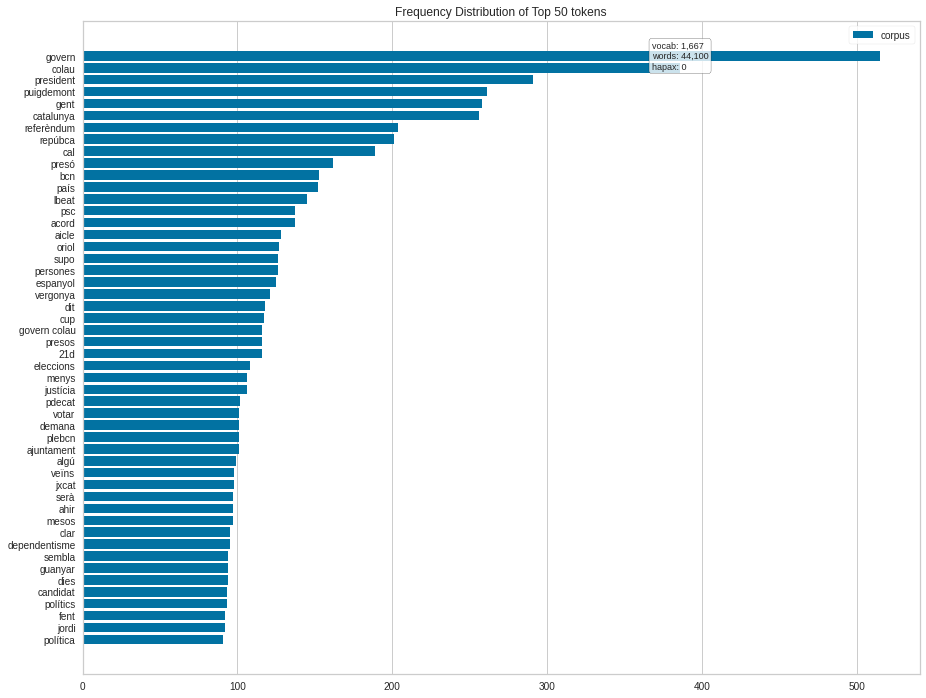

' Catalunya politic keywords extracted from troll data\nCA:\ngovern, president, repúbca, puigdemont, gent, catalunya, colau, presos, presó\n,jxcat, justicia, vergonya, referèndum, pdecat, cup, eleccions, eleccion,persones,\nfemxarxa,\nES:\ngobierno,vox,catalanes,gente,prisión,ciudadanos,dependencia, dependentista, hablemos,\nderechos,Sánchez,medios,Cataluña,psoe,pse,andalucia,1o,cárcel,derechos humanos,\nelecciones, humanos, políticos, cambio\n'

In [ ]:
vect = CountVectorizer(stop_words=sorted(my_stopwords), min_df=10, ngram_range=(1,2))
docs = vect.fit_transform(cat_tweets.clean_tweet_text.dropna())
features = vect.get_feature_names_out()
plt.figure(figsize=(15,12))
visualiser = FreqDistVisualizer(features=features)
visualiser.fit(docs)
visualiser.show()
plt.show()
''' Catalunya politic keywords extracted from troll data
CA:
govern, president, repúbca, puigdemont, gent, catalunya, colau, presos, presó
,jxcat, justicia, vergonya, referèndum, pdecat, cup, eleccions, eleccion,persones,
femxarxa,
ES:
gobierno,vox,catalanes,gente,prisión,ciudadanos,dependencia, dependentista, hablemos,
derechos,Sánchez,medios,Cataluña,psoe,pse,andalucia,1o,cárcel,derechos humanos,
elecciones, humanos, políticos, cambio
'''

**Random tweets** (before filtering by topic):

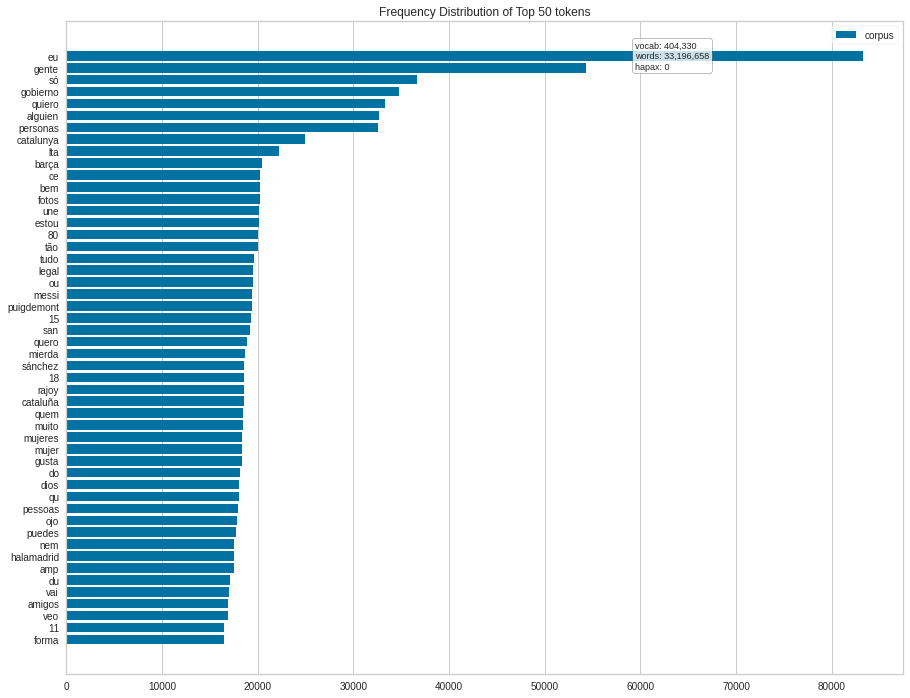

' Catalunya politic keywords extracted from random data\n\n'

In [ ]:
# More words that are frequent in the random sample but unrelated to politics.
# (A missing comma after 'quiero' joins it with 'alguien' into one entry.)
my_rand_stopwords = ['não','vida','madrid','via','vía','uma','mais','mundo','casa',\
                     'fez','est','mañana','sō','año','semana','já','2018','quiero'\
                     'alguien','real','gol','historia','país','mha','ter','amor',\
                     'noche','puta','madre','grande','20','equipo','vor','tenho',
                     'quando','foto','ita','twier','mesmo','30','cara','vou','pasa',\
                     'pour','visto']
my_stopwords = set(list(my_stopwords)+my_rand_stopwords)
vect = CountVectorizer(stop_words=sorted(my_stopwords), min_df=10, ngram_range=(1,2))
docs = vect.fit_transform(es_tweets.clean_tweet_text.dropna())
features = vect.get_feature_names_out()
plt.figure(figsize=(15,12))
visualiser = FreqDistVisualizer(features=features)
visualiser.fit(docs)
visualiser.show()
plt.show()
''' Catalunya politic keywords extracted from random data

'''

The troll vocabulary is clearly about Catalan politics: *govern*, *president*, *Puigdemont*, *Colau*, *referèndum*, *presos/presó* (prisoners/prison), *JxCat*, *CUP*, *eleccions*. These words were used as keywords to select comparable tweets from the random sample (see *Building a comparable control group*). Tokens such as *repúbca* and *aicle* come from the abbreviation-removal issue described at the top.

# Are the trolls bots?

## Repetitive tweets

In [ ]:
cat_tweets.columns

Index(['tweetid', 'userid', 'user_display_name', 'user_screen_name',
       'user_reported_location', 'user_profile_description',
       'user_profile_url', 'follower_count', 'following_count',
       'account_creation_date', 'account_language', 'tweet_language',
       'tweet_text', 'tweet_time', 'tweet_client_name', 'in_reply_to_userid',
       'in_reply_to_tweetid', 'quoted_tweet_tweetid', 'is_retweet',
       'retweet_userid', 'retweet_tweetid', 'latitude', 'longitude',
       'quote_count', 'reply_count', 'like_count', 'retweet_count', 'hashtags',
       'urls', 'user_mentions', 'poll_choices', 'is_com_or_rt', 'abbr_count',
       'tweet_len', 'stopwords_count', 'hashtag_count', 'mention_count',
       'caps_to_normal', 'Date', 'Time', 'mensh', 'mensh_user_desc',
       'num_in_name', 'Acc_age', 'follower_to_following', 'clean_tweet_text',
       'clean_user_profile_description'],
      dtype='object')

In [ ]:
(cat_tweets.clean_tweet_text.value_counts()/cat_tweets.clean_tweet_text.value_counts().sum()).mean() 
# Average share of each distinct text is tiny: tweets are rarely repeated word for word.

0.00013726835964310123

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB o

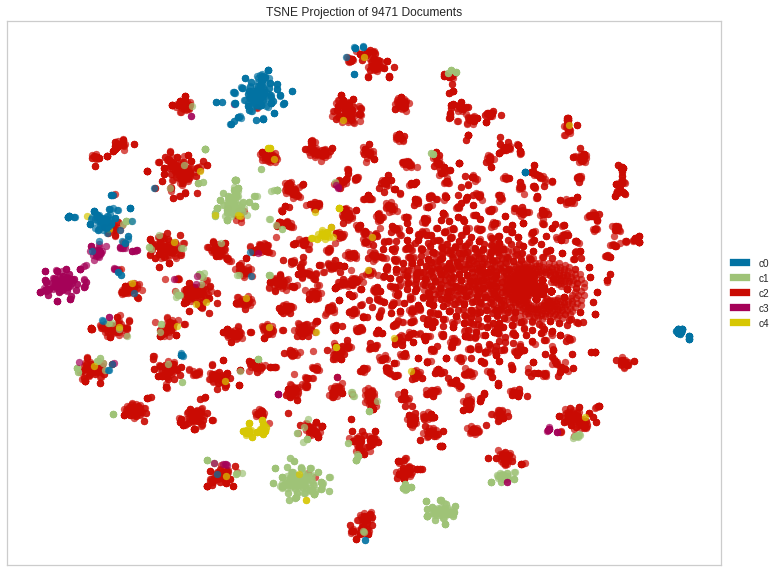

In [ ]:
from sklearn.cluster import KMeans
CLS_NUM = 5
corpus = list(cat_tweets.clean_tweet_text.dropna().values)
tfidf = TfidfVectorizer(stop_words=sorted(my_stopwords), min_df=10, ngram_range=(1,2))
docs = tfidf.fit_transform(corpus)
# K-means on TF-IDF vectors, visualised with t-SNE: are there distinct topic clusters?
clusters = KMeans(n_clusters=CLS_NUM)
clusters.fit(docs)
# This takes a while to re-run
plt.figure(figsize=(16,10))
tsne = TSNEVisualizer()
tsne.fit(docs, ["c{}".format(c) for c in clusters.labels_])
tsne.show()
plt.show()

Most troll tweets fall into one large, diffuse cluster (c2), with a few small, tight groups of near-duplicate messages.

## Tweet time and time interval distribution

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


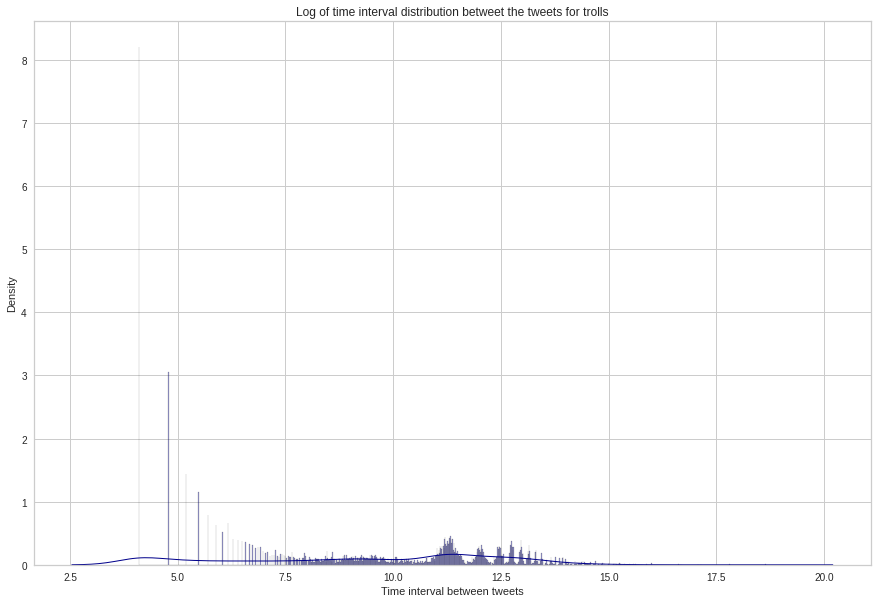

In [ ]:
# Seconds between consecutive tweets of the same troll account.
tweet_times = pd.to_datetime(cat_tweets.tweet_time, format='%Y-%m-%d %H:%M:%S')
diff_time = (cat_tweets.assign(t=tweet_times)
             .dropna(subset=['userid', 't'])
             .sort_values('t')
             .groupby('userid')['t'].diff()
             .dt.total_seconds()
             .dropna())

plt.figure(figsize=(15, 10))
sns.histplot(np.log(diff_time[diff_time > 0]), bins=1000, kde=True, stat='density',
             color='darkblue', edgecolor='black', line_kws={'linewidth': 1})
plt.title('Log of time interval distribution betweet the tweets for trolls')
plt.xlabel('Time interval between tweets')
plt.show()

If the trolls were bots posting on a schedule, the gaps between their tweets would cluster tightly. Instead they spread from minutes to months. The x-axis is log(seconds): 4.1 ≈ 1 minute, 8.2 ≈ 1 hour, 11.4 ≈ 1 day. The tall spikes on the left appear because timestamps are rounded to the minute.

# Building a comparable control group

The random sample covers every topic. To compare like with like, keep only random tweets that are about Catalan politics, selected either by **keywords** in the text or by **hashtags**.

In [ ]:
# Political keywords taken from the troll token frequencies above (Catalan and Spanish).
keywords = ['govern', 'president', 'repúbca', 'puigdemont', 'gent', 'catalunya',
            'colau', 'presos', 'presó', 'jxcat', 'justicia', 'vergonya', 'referèndum',
            'pdecat', 'cup', 'eleccions', 'eleccion', 'persones', 'femxarxa', 'gobierno',
            'vox', 'catalanes', 'gente', 'prisión', 'ciudadanos', 'dependencia', 'dependentista',
            'hablemos', 'derechos', 'Sánchez', 'medios', 'Cataluña', 'psoe', 'pse',
            'andalucia', '1o', 'cárcel', 'derechos humanos', 'elecciones', 'humanos',
            'políticos', 'cambio']
keyhashtags = all_hashtags


def contains_any(data, keys):
    """1 if any of the keys occurs (as a substring) in data, else 0."""
    return int(any(key in data for key in keys))


# (In the submitted version these two column names were swapped; the selections below are unchanged.)
es_tweets['is_sample_key'] = es_tweets.clean_tweet_text.dropna().apply(contains_any, keys=keywords)
es_tweets['is_sample_hash'] = es_tweets.hashtags.dropna().apply(contains_any, keys=keyhashtags)

**Random tweets selected by keyword:**

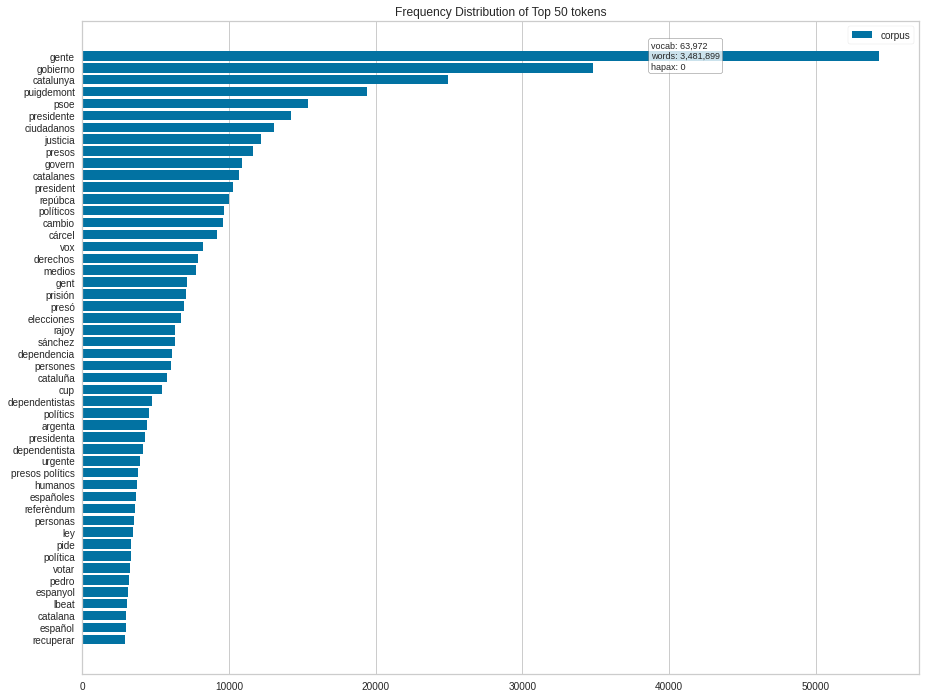

In [ ]:
vect = CountVectorizer(stop_words=sorted(my_stopwords), min_df=10, ngram_range=(1,2))
docs = vect.fit_transform(es_tweets.clean_tweet_text.dropna()[es_tweets.is_sample_key == 1])
features = vect.get_feature_names_out()
plt.figure(figsize=(15,12))
visualiser = FreqDistVisualizer(features=features)
visualiser.fit(docs)
visualiser.show()
plt.show()

**Random tweets selected by hashtag:**

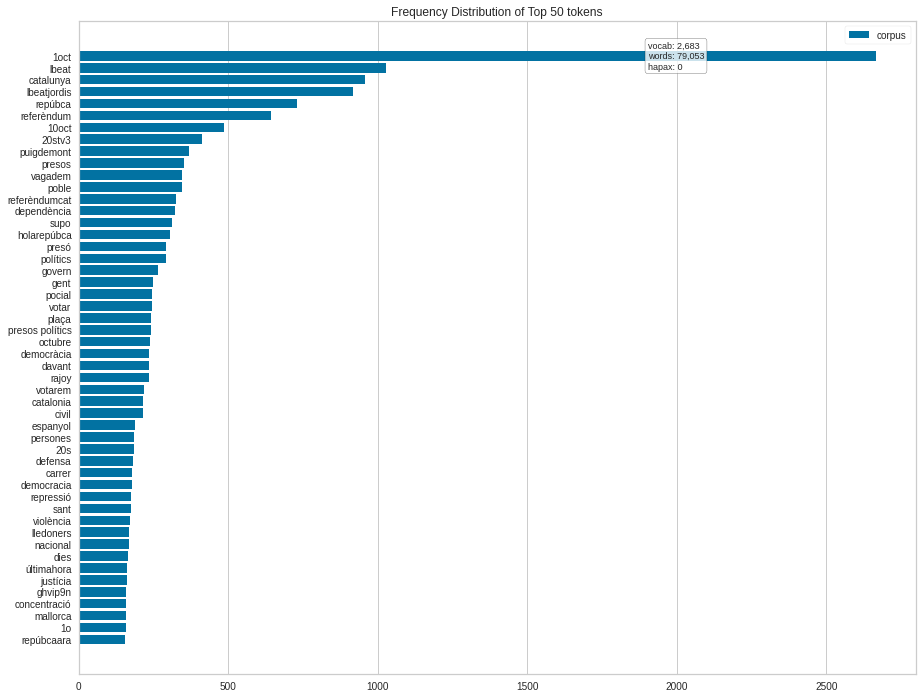

In [ ]:
vect = CountVectorizer(stop_words=sorted(my_stopwords), min_df=10, ngram_range=(1,2))
docs = vect.fit_transform(es_tweets.clean_tweet_text.dropna()[es_tweets.is_sample_hash == 1])
features = vect.get_feature_names_out()
plt.figure(figsize=(15,12))
visualiser = FreqDistVisualizer(features=features)
visualiser.fit(docs)
visualiser.show()
plt.show()
    

Selecting by **keyword** gives a much larger sample, and its most frequent tokens are clearly about Catalan politics. The keyword-selected tweets are therefore used as the control ("random") group from here on.

In [ ]:
es_tweets = es_tweets[es_tweets.is_sample_key == 1]

In [ ]:
save_df(es_tweets, 'random_sample')
save_df(cat_tweets, 'troll_sample')

# Account statistics: trolls vs control group

All bar charts show **shares within each group**, so the ~9.5k troll tweets and ~390k control tweets can be compared directly.

## Date and Time

In [ ]:
def diff_plot_bar(df_troll,df_random, title_, xlabel_, format_='%Y-%m', rotation_=ROTATION, figsize_=FIGSIZE, ylabel_=YLABEL, opacity_=OPACITY):

  result_date_freq = diff_df_freq(df_troll,df_random)

  plt.figure(figsize=figsize_)
  plt.bar(pd.to_datetime(result_date_freq.index, format=format_), result_date_freq.iloc[:,0], alpha= opacity_, label='Random Tweets')
  plt.bar(pd.to_datetime(result_date_freq.index, format=format_), result_date_freq.iloc[:,1], alpha= opacity_, label='Troll Tweets')
  plt.legend(loc=0, fontsize=18)
  #plt.xticks([]) #just uncomment for time
  plt.xticks(rotation=rotation_)
  plt.xlabel(xlabel_)
  plt.ylabel(ylabel_)
  plt.title(title_)
  plt.show()

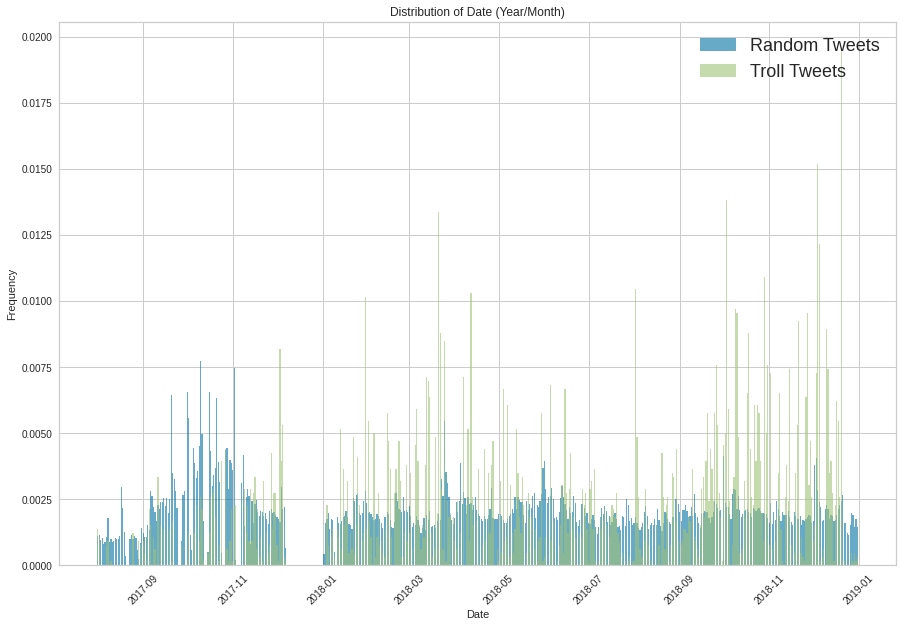

In [ ]:
troll_date = pd.DataFrame(cat_tweets.Date.value_counts().sort_index())
random_date = pd.DataFrame(es_tweets.Date.value_counts().sort_index())
diff_plot_bar(troll_date, random_date, title_='Distribution of Date (Year/Month)', xlabel_ = 'Date')
del troll_date
del random_date

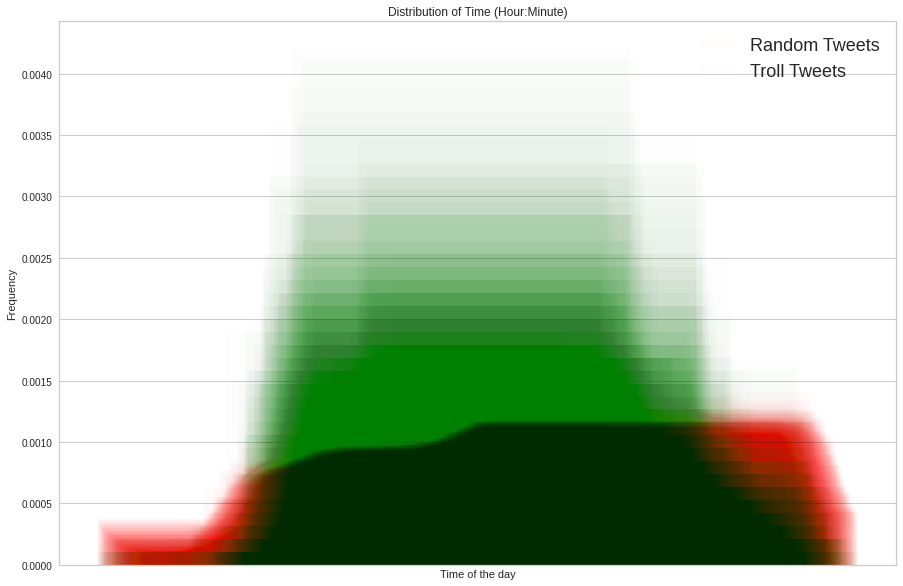

In [ ]:
troll_time = pd.DataFrame(cat_tweets.Time.value_counts().sort_index())
random_time = pd.DataFrame(es_tweets.Time.value_counts().sort_index())
diff_plot_bar(troll_time, random_time, title_='Distribution of Time (Hour:Minute)', xlabel_ = 'Time of the day', format_='%H:%M', opacity_=0.01)
del troll_time
del random_time

In [ ]:
def parse_time2(df, col_name):
  df[col_name] = pd.to_datetime(df[col_name], format='%Y %m %d %H:%M')
  df['Date2'] = df[col_name].dt.strftime('%Y %m')
  df['Time2'] = df[col_name].dt.strftime('%H')
  
  return df

In [ ]:
cat_tweets = parse_time2(cat_tweets, 'tweet_time')
es_tweets = parse_time2(es_tweets, 'tweet_time')

In [ ]:
def diff_plot_bar2(df_troll,df_random, title_, xlabel_, rotation_=ROTATION, figsize_=FIGSIZE, ylabel_=YLABEL, opacity_=OPACITY):

  result_date_freq = diff_df_freq(df_troll,df_random)

  plt.figure(figsize=figsize_)
  plt.bar(result_date_freq.index, result_date_freq.iloc[:,0], alpha= opacity_, label='Random Tweets', color='orange')
  plt.bar(result_date_freq.index, result_date_freq.iloc[:,1], alpha= opacity_, label='Troll Tweets', color='blue')
  plt.legend(loc=0, fontsize=18)
  plt.xticks(rotation=rotation_)
  plt.xlabel(xlabel_)
  plt.ylabel(ylabel_)
  plt.title(title_)
  plt.show()

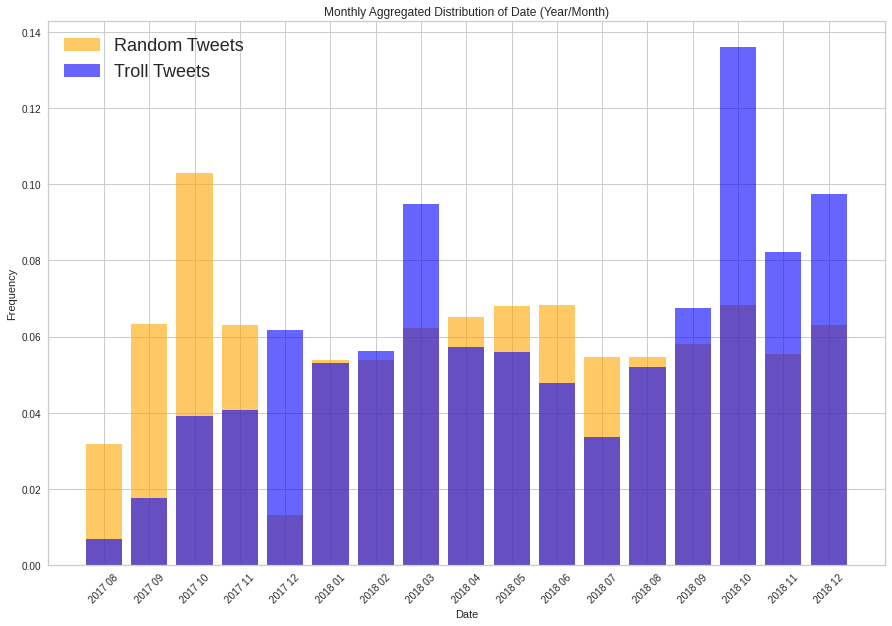

In [ ]:
troll_date = pd.DataFrame(cat_tweets.Date2.value_counts().sort_index())
random_date = pd.DataFrame(es_tweets.Date2.value_counts().sort_index())
diff_plot_bar2(troll_date, random_date, title_='Monthly Aggregated Distribution of Date (Year/Month)', xlabel_ = 'Date')
del troll_date
del random_date

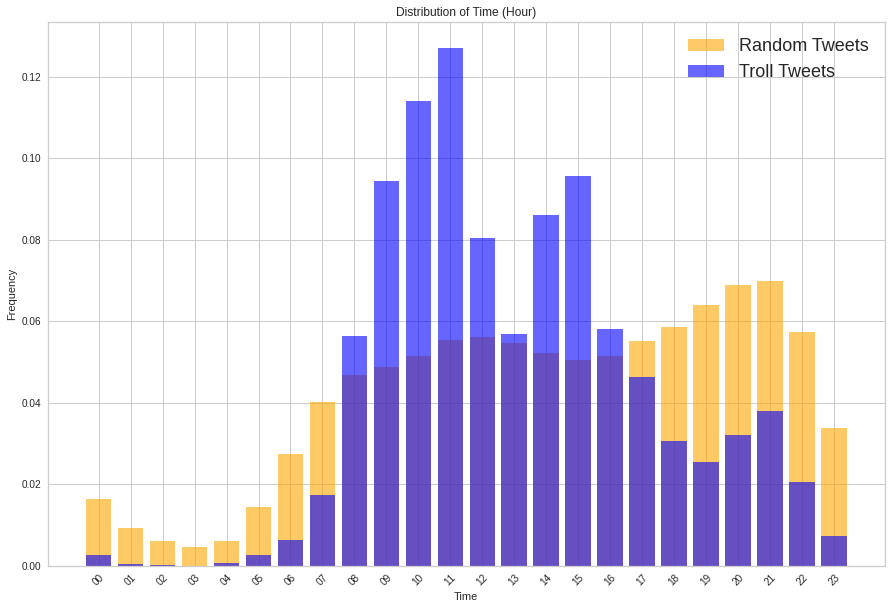

In [ ]:
troll_time = pd.DataFrame(cat_tweets.Time2.value_counts().sort_index())
random_time = pd.DataFrame(es_tweets.Time2.value_counts().sort_index())
diff_plot_bar2(troll_time, random_time, title_='Distribution of Time (Hour)', xlabel_ = 'Time',)
del troll_time
del random_time

* **Months:** the control group is most active around the October 2017 referendum. Troll activity peaks in March 2018 and especially October 2018 (first anniversary of the referendum), and stays high to December 2018.
* **Hours:** trolls tweet mostly between 09:00 and 15:00, like a working day, and almost never at night. The control group peaks in the evening (18:00–22:00).

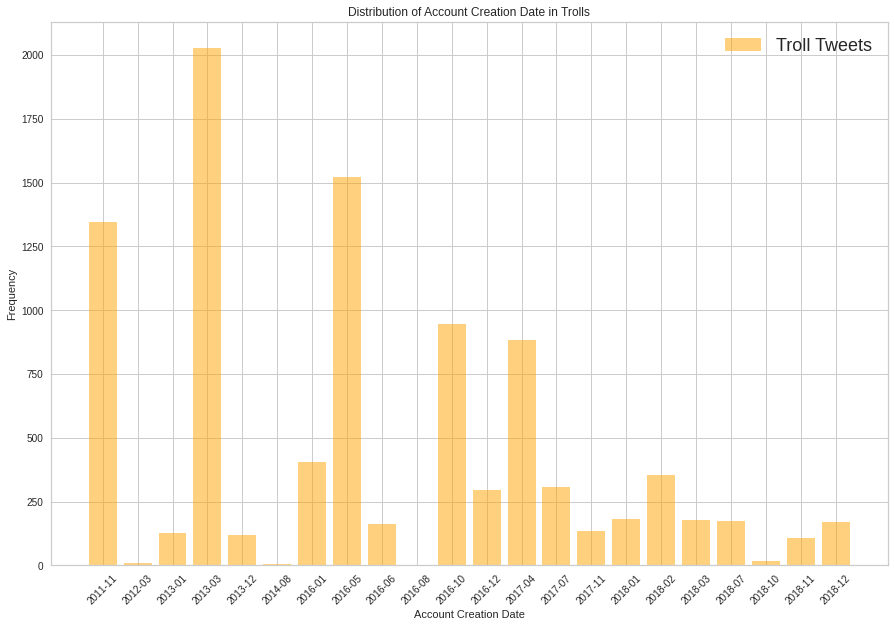

In [ ]:
troll_creation_date = pd.DataFrame(pd.to_datetime(cat_tweets.account_creation_date, format='%Y-%m-%d').dt.strftime('%Y-%m').value_counts().sort_index())
plt.figure(figsize=(15,10))
plt.bar(troll_creation_date.index, troll_creation_date.iloc[:,0], alpha= 0.5, label='Troll Tweets', color='orange')
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=45)
plt.xlabel('Account Creation Date')
plt.ylabel('Frequency')
plt.title('Distribution of Account Creation Date in Trolls')
plt.show()
#del troll_creation_date

These are tweet counts by the creation month of the account that posted them. Troll accounts were created in a few bursts (Nov 2011, Mar 2013, May 2016, Oct 2016, Apr 2017), which suggests accounts created or bought in batches.

## Num. in name, Folower/Following, Acc Age

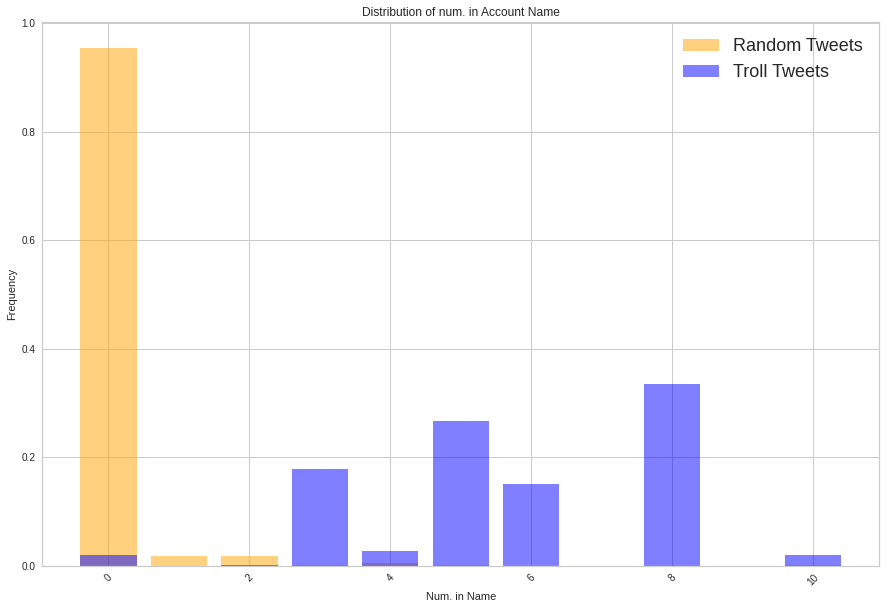

In [ ]:
troll_nin = pd.DataFrame(cat_tweets.num_in_name.value_counts().sort_index())
random_nin = pd.DataFrame(es_tweets.num_in_name.value_counts().sort_index())
result_date_freq = diff_df_freq(troll_nin,random_nin)
plt.figure(figsize=(15,10))
plt.bar(result_date_freq.index, result_date_freq.iloc[:,0], alpha= 0.5, label='Random Tweets', color='orange')
plt.bar(result_date_freq.index, result_date_freq.iloc[:,1], alpha= 0.5, label='Troll Tweets', color='blue')
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=45)
plt.xlabel('Num. in Name')
plt.ylabel('Frequency')
plt.title('Distribution of num. in Account Name')
plt.show()
del troll_nin
del random_nin

About 95% of control accounts have no digits in their display name. Most troll display names contain 3–8 digits, which is typical of auto-generated names.

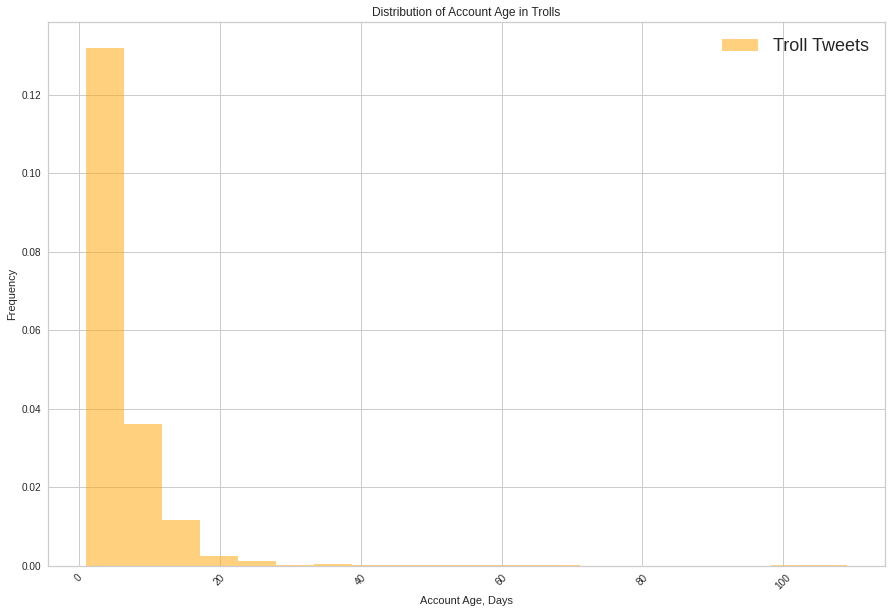

In [ ]:
troll_age = pd.DataFrame(cat_tweets.Acc_age.value_counts().sort_index())
plt.figure(figsize=(15,10))
plt.hist(troll_age.iloc[:,0], alpha= 0.5, label='Troll Tweets', color='orange', bins=20,density=True)
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=45)
plt.xlabel('Account Age, Days')
plt.ylabel('Frequency')
plt.title('Distribution of Account Age in Trolls')
plt.show()
del troll_age


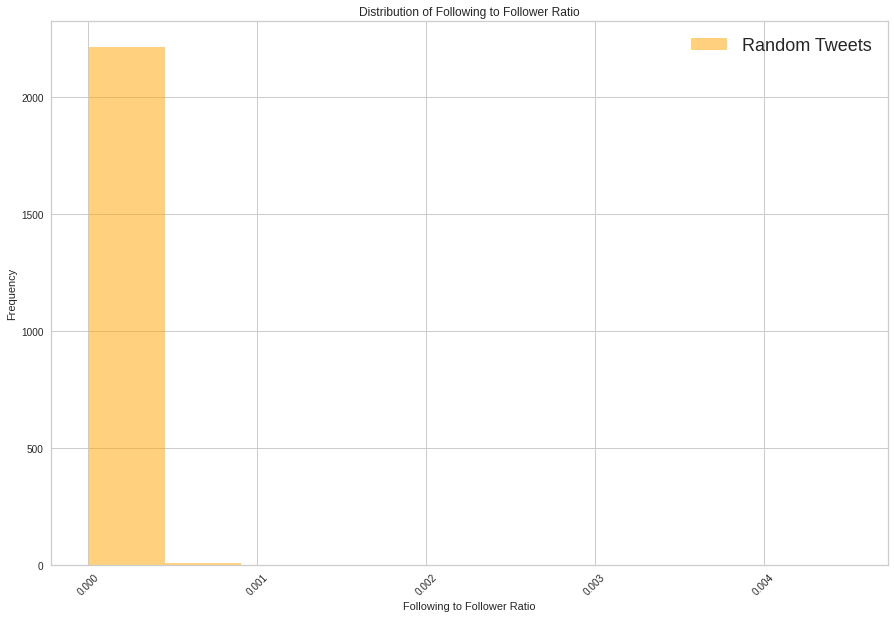

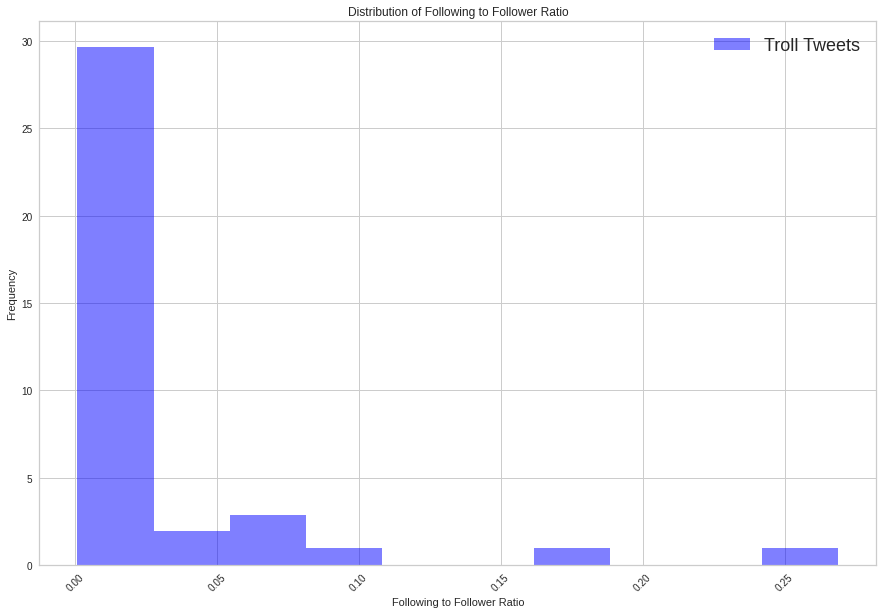

In [ ]:
troll_ff = pd.DataFrame(cat_tweets.follower_to_following.value_counts().sort_index())
random_ff = pd.DataFrame(es_tweets.follower_to_following.value_counts().sort_index())
result_date_freq = diff_df_freq(troll_ff,random_ff)
plt.figure(figsize=(15,10))
plt.hist( result_date_freq.iloc[:,0], alpha= 0.5, label='Random Tweets', color='orange', bins=10,density=True)
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=45)
plt.xlabel('Following to Follower Ratio')
plt.ylabel('Frequency')
plt.title('Distribution of Following to Follower Ratio')
plt.show()

plt.figure(figsize=(15,10))
plt.hist(result_date_freq.iloc[:,1], alpha= 0.5, label='Troll Tweets', color='blue', bins=10,density=True)
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=45)
plt.xlabel('Following to Follower Ratio')
plt.ylabel('Frequency')
plt.title('Distribution of Following to Follower Ratio')
plt.show()

del troll_ff
del random_ff

#FIX FREQUENCY HERE

*Caveat:* this histogram and the account-age one above show how often each value occurs, not the values themselves, so they are hard to read. Plotting `follower_to_following` directly (on a log scale) for both groups would be the correct comparison.

In [ ]:
# Self-reported locations of both groups (shares). Not plotted: locations need heavy normalisation,
# e.g. 'Barcelona, Spain' vs 'Barcelona, Espanya'.
troll_loc = pd.DataFrame(cat_tweets.user_reported_location.value_counts().sort_values())
random_loc = pd.DataFrame(es_tweets.user_reported_location.value_counts().sort_values())
location_freq = diff_df_freq(troll_loc, random_loc)
del troll_loc
del random_loc

In [ ]:
location_freq.dropna()  # locations used by both groups (x = random, y = troll)

,user_reported_location_x,user_reported_location_y
"Terrassa, España",0.000130,0.004978
"Manresa, Espanya",0.000187,0.033796
"Girona, Catalunya",0.000371,0.000786
"Barcelona, Spain",0.000424,0.048729
"Barcelona, Espanya",0.001218,0.224260
"Barcelona, Cataluña",0.008015,0.105580
"Barcelona, Catalunya",0.009050,0.260676
Barcelona,0.026569,0.124181
"Barcelona, España",0.039831,0.197013


# Tweet statistics: trolls vs control group

In [ ]:
cat_tweets.columns

Index(['tweetid', 'userid', 'user_display_name', 'user_screen_name',
       'user_reported_location', 'user_profile_description',
       'user_profile_url', 'follower_count', 'following_count',
       'account_creation_date', 'account_language', 'tweet_language',
       'tweet_text', 'tweet_time', 'tweet_client_name', 'in_reply_to_userid',
       'in_reply_to_tweetid', 'quoted_tweet_tweetid', 'is_retweet',
       'retweet_userid', 'retweet_tweetid', 'latitude', 'longitude',
       'quote_count', 'reply_count', 'like_count', 'retweet_count', 'hashtags',
       'urls', 'user_mentions', 'poll_choices', 'is_com_or_rt', 'abbr_count',
       'tweet_len', 'stopwords_count', 'hashtag_count', 'mention_count',
       'caps_to_normal', 'Date', 'Time', 'mensh', 'mensh_user_desc',
       'num_in_name', 'Acc_age', 'follower_to_following', 'clean_tweet_text',
       'clean_user_profile_description'],
      dtype='object')

In [ ]:
cat_tweets.is_com_or_rt = [0 if i==0 or i==None else 1 for i in cat_tweets.is_com_or_rt]
es_tweets.is_com_or_rt = [0 if i==0 or i==None else 1 for i in es_tweets.is_com_or_rt]

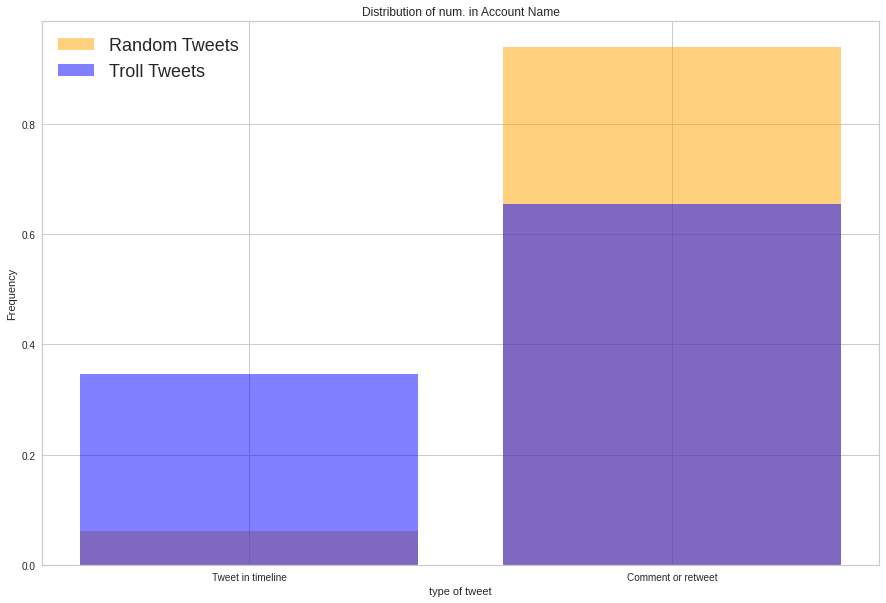

In [ ]:
#is_com_or_rt
troll_com_rt = pd.DataFrame(cat_tweets.is_com_or_rt.value_counts().sort_index())
random_com_rt = pd.DataFrame(es_tweets.is_com_or_rt.value_counts().sort_index())
LABELS = ['Tweet in timeline', 'Comment or retweet']
result_date_freq = diff_df_freq(troll_com_rt,random_com_rt)
result_date_freq.index= LABELS
plt.figure(figsize=(15,10))
plt.bar(result_date_freq.index, result_date_freq.iloc[:,0], alpha= 0.5, label='Random Tweets', color='orange')
plt.bar(result_date_freq.index, result_date_freq.iloc[:,1], alpha= 0.5, label='Troll Tweets', color='blue')
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=0)
plt.xlabel('type of tweet')
plt.ylabel('Frequency')
plt.title('Distribution of num. in Account Name')
plt.show()
del troll_com_rt
del random_com_rt

Troll accounts post far more original tweets (~35% vs ~6%). Control tweets are mostly retweets or replies. *(The plot title is a copy-paste leftover; the x-axis shows the tweet type.)*

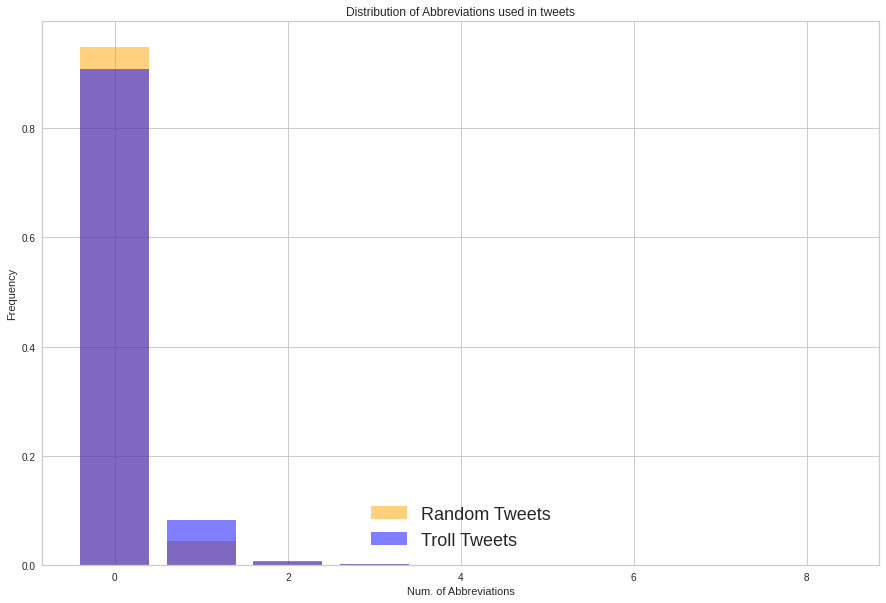

In [ ]:
#abbr_count
troll_abbr_count = pd.DataFrame(cat_tweets.abbr_count.value_counts().sort_index())
random_abbr_count = pd.DataFrame(es_tweets.abbr_count.dropna().apply(int).value_counts().sort_index())
result_date_freq = diff_df_freq(troll_abbr_count, random_abbr_count)
plt.figure(figsize=(15,10))
plt.bar(result_date_freq.index, result_date_freq.iloc[:,0], alpha= 0.5, label='Random Tweets', color='orange')
plt.bar(result_date_freq.index, result_date_freq.iloc[:,1], alpha= 0.5, label='Troll Tweets', color='blue')
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=0)
plt.xlabel('Num. of Abbreviations')
plt.ylabel('Frequency')
plt.title('Distribution of Abbreviations used in tweets')
plt.show()
del troll_abbr_count
del random_abbr_count

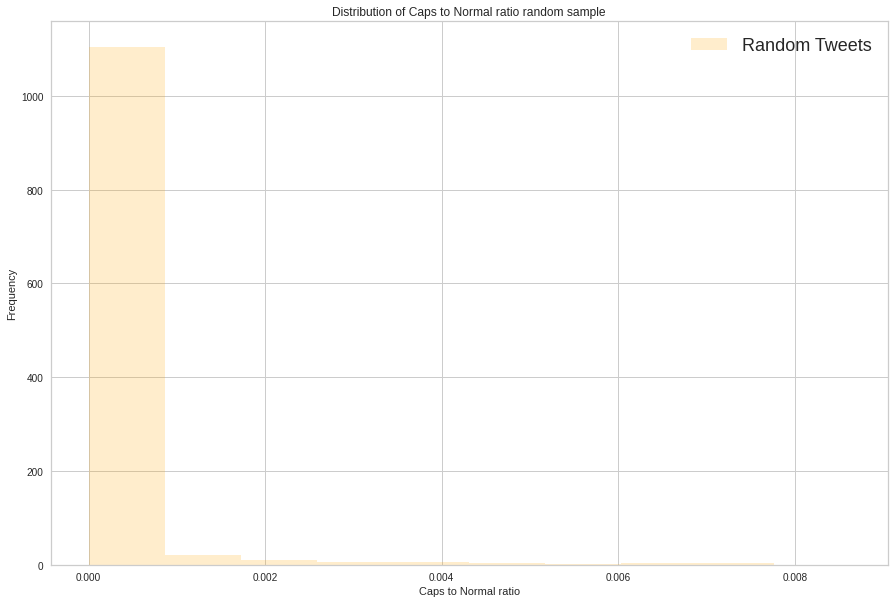

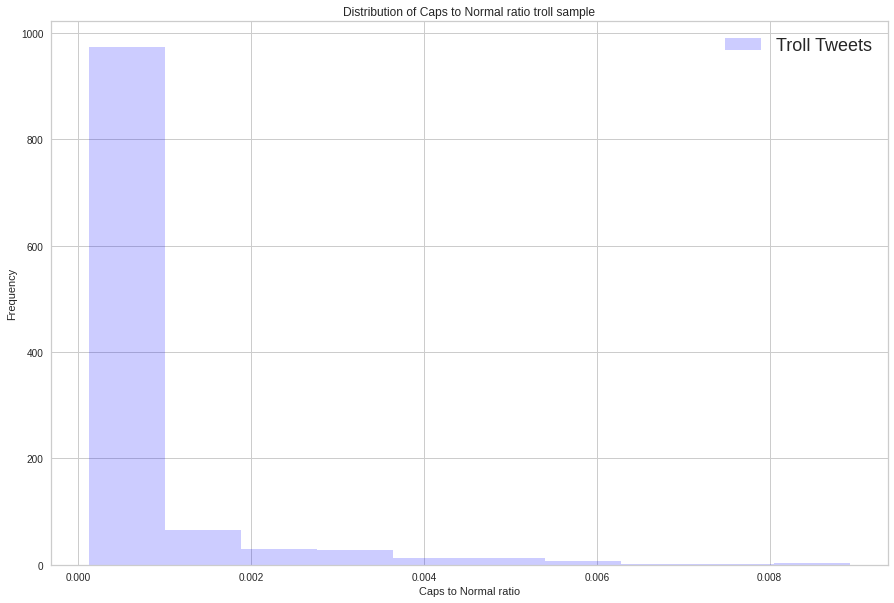

In [ ]:
#caps_to_normal
troll_caps_norm = pd.DataFrame(cat_tweets.caps_to_normal.value_counts().sort_index())
random_caps_norm = pd.DataFrame(es_tweets.caps_to_normal.value_counts().sort_index())
result_date_freq = diff_df_freq(troll_caps_norm, random_caps_norm)
plt.figure(figsize=(15,10))
plt.hist(result_date_freq.iloc[:,0], alpha= 0.2, label='Random Tweets', color='orange',density=True)
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=0)
plt.xlabel('Caps to Normal ratio')
plt.ylabel('Frequency')
plt.title('Distribution of Caps to Normal ratio random sample')
#plt.xlim((0,2))
plt.show()
plt.figure(figsize=(15,10))
plt.hist(result_date_freq.iloc[:,1], alpha= 0.2, label='Troll Tweets', color='blue',density=True)
plt.legend(loc=0, fontsize=18)
plt.xticks(rotation=0)
plt.xlabel('Caps to Normal ratio')
plt.ylabel('Frequency')
plt.title('Distribution of Caps to Normal ratio troll sample')
#plt.xlim((0,2))
plt.show()
del troll_caps_norm
del random_caps_norm

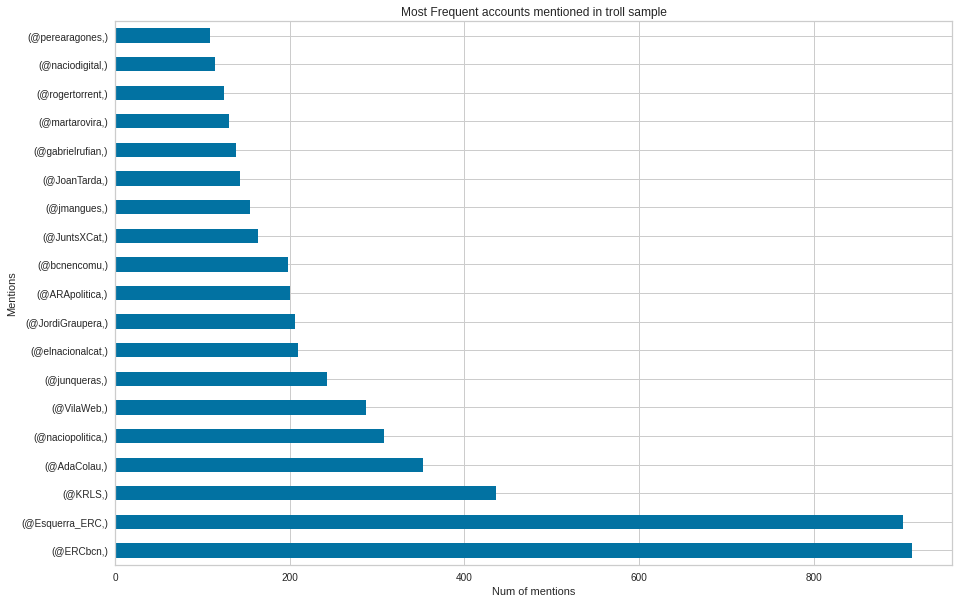

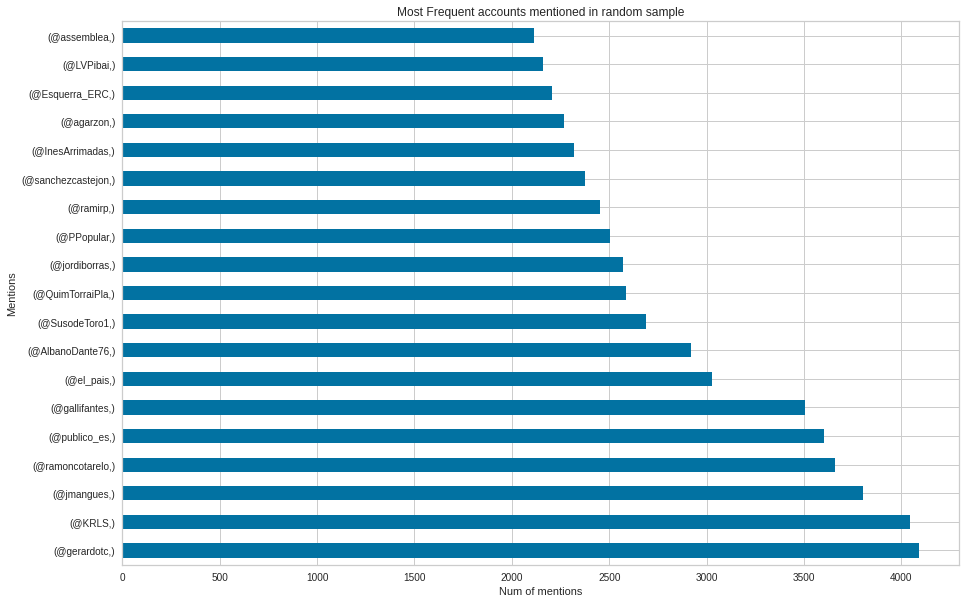

In [ ]:
#mensh
from ast import literal_eval
mensions_cat = []
for lst in cat_tweets.mensh.dropna():
    mensions_cat += literal_eval(lst)
mensions_es = []
for lst in es_tweets.mensh.dropna():
    mensions_es += literal_eval(lst)
plt.figure(figsize=(15,10))
pd.DataFrame(mensions_cat).value_counts().sort_values(ascending=False)[1:20].plot(kind='barh')
plt.title('Most Frequent accounts mentioned in troll sample')
plt.xlabel('Num of mentions')
plt.ylabel('Mentions')
plt.show()

plt.figure(figsize=(15,10))
pd.DataFrame(mensions_es).value_counts().sort_values(ascending=False)[1:20].plot(kind='barh')
plt.title('Most Frequent accounts mentioned in random sample')
plt.xlabel('Num of mentions')
plt.ylabel('Mentions')
plt.show()

Mentions inside profile descriptions were also checked, but they were not informative.

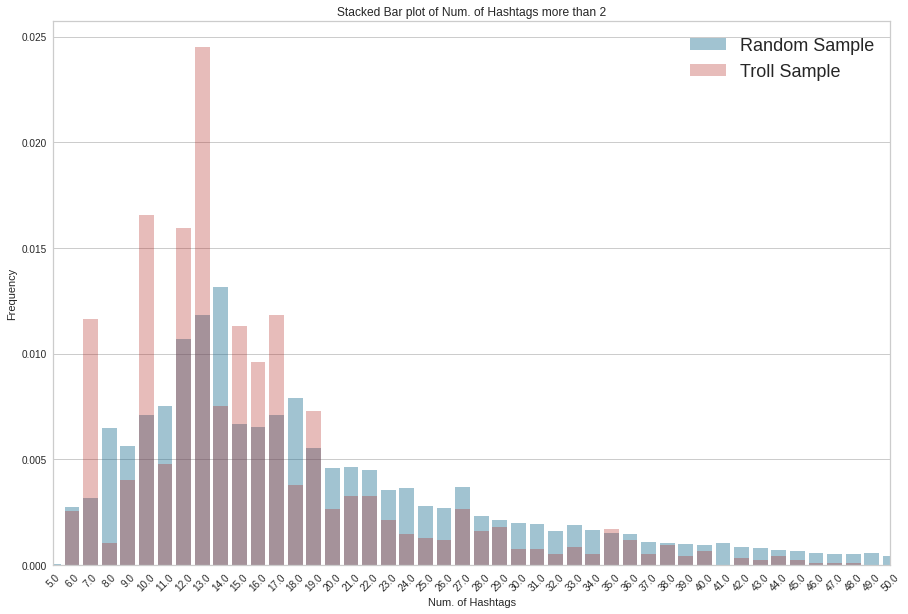

In [ ]:
#hashtag count
troll_hash_count = pd.DataFrame(cat_tweets.hashtag_count.value_counts().sort_index())
random_hash_count = pd.DataFrame(es_tweets.hashtag_count.dropna().value_counts().sort_index())
result_date_freq = diff_df_freq(troll_hash_count, random_hash_count)

# creating subplots
ax = plt.subplots(figsize=(15,10))
  
# plotting columns
ax = sns.barplot(x=result_date_freq.index[1:], y=result_date_freq.iloc[1:,0], color='b', label='Random Sample', alpha=0.4)
ax = sns.barplot(x=result_date_freq.index[1:], y=result_date_freq.iloc[1:,1], color='r', label='Troll Sample', alpha=0.3)
plt.legend(loc='upper right', fontsize=18)
plt.xticks(rotation=45)
plt.xlabel('Num. of Hashtags')
plt.ylabel('Frequency')
plt.title('Stacked Bar plot of Num. of Hashtags more than 2')
plt.xlim((0,45))
# renaming the axes
  
# visulaizing illustration
plt.show()

del troll_hash_count
del random_hash_count

`hashtag_count` is the `len()` of the raw `hashtags` field, which is stored as text, so it counts characters rather than hashtags (2 = an empty list `[]`). Roughly 80% of tweets in both groups have **no** hashtags; the plot shows the rest. The control group has more extreme values, partly because it is a much larger sample.

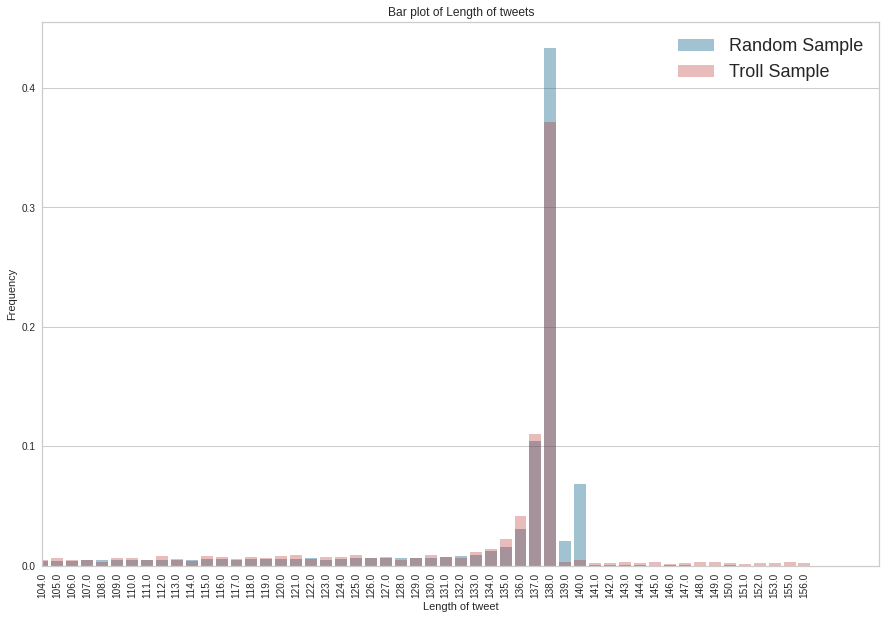

In [ ]:
# tweet_len biased by abnormal text
troll_tweet_len = pd.DataFrame(cat_tweets.tweet_len.dropna().value_counts().sort_index())
random_tweet_len = pd.DataFrame(es_tweets.tweet_len.dropna().value_counts().sort_index())
result_date_freq = diff_df_freq(troll_tweet_len, random_tweet_len)

# creating subplots
ax = plt.subplots(figsize=(15,10))
  
# plotting columns
ax = sns.barplot(x=result_date_freq.index, y=result_date_freq.iloc[:,0], color='b', label='Random Sample', alpha=0.4)
ax = sns.barplot(x=result_date_freq.index, y=result_date_freq.iloc[:,1], color='r', label='Troll Sample', alpha=0.3)
plt.legend(loc='upper right', fontsize=18)
plt.xticks(rotation=90)
plt.xlabel('Length of tweet')
plt.ylabel('Frequency')
plt.title('Bar plot of Length of tweets')
plt.xlim((100,156))
# renaming the axes
  
# visulaizing illustration
plt.show()

del troll_tweet_len
del random_tweet_len

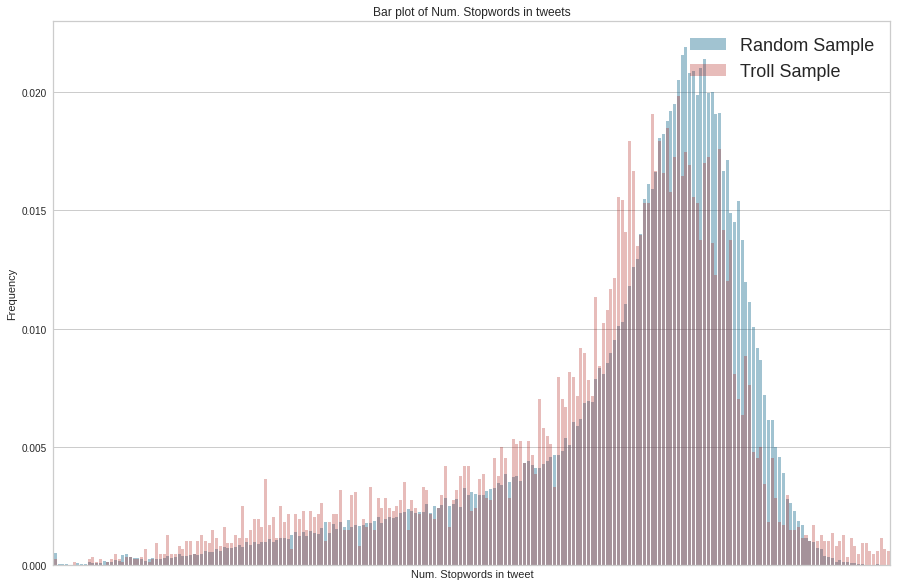

In [ ]:
#stopwords_count
troll_stopwords_count = pd.DataFrame(cat_tweets.stopwords_count.dropna().value_counts().sort_index())
random_stopwords_count = pd.DataFrame(es_tweets.stopwords_count.dropna().value_counts().sort_index())
result_date_freq = diff_df_freq(troll_stopwords_count, random_stopwords_count)

# creating subplots
ax = plt.subplots(figsize=(15,10))
  
# plotting columns
ax = sns.barplot(x=result_date_freq.index, y=result_date_freq.iloc[:,0], color='b', label='Random Sample', alpha=0.4)
ax = sns.barplot(x=result_date_freq.index, y=result_date_freq.iloc[:,1], color='r', label='Troll Sample', alpha=0.3)
plt.legend(loc='upper right', fontsize=18)
plt.xticks([])
plt.xlabel('Num. Stopwords in tweet')
plt.ylabel('Frequency')
plt.title('Bar plot of Num. Stopwords in tweets')
#plt.xlim((100,156))
# renaming the axes
  
# visulaizing illustration
plt.show()

del troll_stopwords_count
del random_stopwords_count

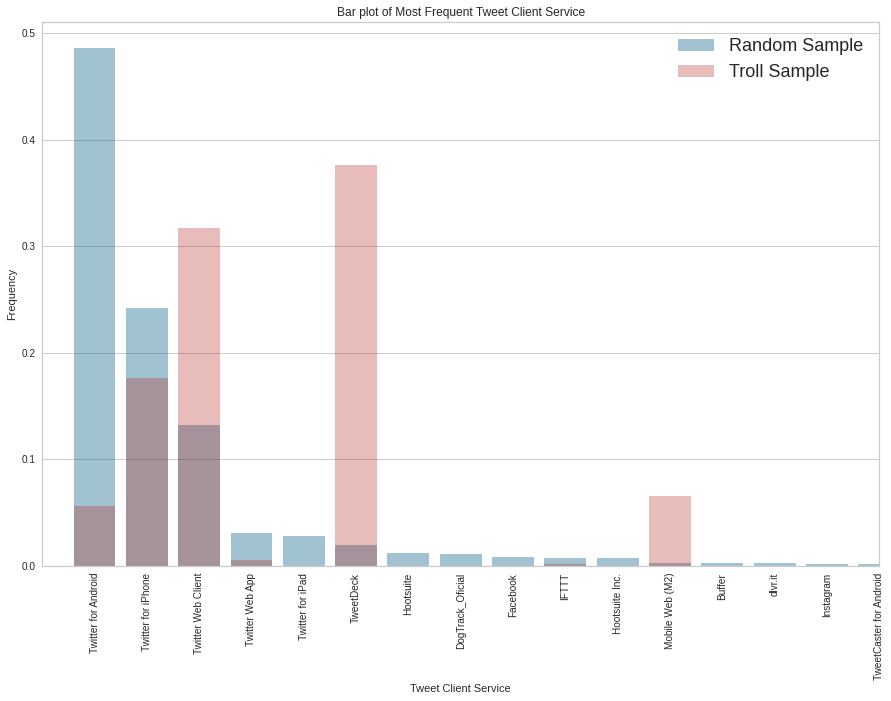

In [ ]:
#device
troll_tweet_client_name = pd.DataFrame(cat_tweets.tweet_client_name.dropna().value_counts().sort_values(ascending=False))
random_tweet_client_name = pd.DataFrame(es_tweets.tweet_client_name.dropna().value_counts().sort_values(ascending=False))
result_date_freq = diff_df_freq(troll_tweet_client_name, random_tweet_client_name)

# creating subplots
ax = plt.subplots(figsize=(15,10))
  
# plotting columns
ax = sns.barplot(x=result_date_freq.index, y=result_date_freq.iloc[:,0], color='b', label='Random Sample', alpha=0.4)
ax = sns.barplot(x=result_date_freq.index, y=result_date_freq.iloc[:,1], color='r', label='Troll Sample', alpha=0.3)
plt.legend(loc='upper right', fontsize=18)
plt.xticks(rotation=90)
plt.xlabel('Tweet Client Service')
plt.ylabel('Frequency')
plt.title('Bar plot of Most Frequent Tweet Client Service')
plt.xlim((-1,15))
# renaming the axes
  
# visulaizing illustration
plt.show()

del troll_tweet_client_name
del random_tweet_client_name

The client app is the most striking difference: trolls post mainly through **TweetDeck** and the **web client**, both desktop tools for managing several accounts. The control group mostly tweets from phones (Android, iPhone).

# Building the modelling datasets

In [ ]:
troll_sample = pd.read_csv(f'{DATA_DIR}/troll_sample.csv')    # troll tweets
random_sample = pd.read_csv(f'{DATA_DIR}/random_sample.csv')  # keyword-filtered control tweets

In [ ]:
print(f"troll_sample shape = {troll_sample.shape}, random_sample shape={random_sample.shape}")

troll_sample shape = (9489, 47), random_sample shape=(389734, 36)


The classes are very imbalanced: about 9.5k troll tweets vs 390k control tweets (≈ 1 : 41). **SMOTE** oversampling is used to balance the training data.

In [ ]:
# Setting y for supervised models.
troll_sample['is_troll'] = np.ones(troll_sample.shape[0])
random_sample['is_troll'] = np.zeros(random_sample.shape[0])

In [ ]:
from langdetect import DetectorFactory, detect

DetectorFactory.seed = 0  # make langdetect deterministic


def detect_lang(data):
    """ISO language code of a text, or None if it cannot be detected (empty text, NaN, ...)."""
    try:
        return detect(data)
    except Exception:
        return None

In [ ]:
troll_sample['lang'] = troll_sample.clean_tweet_text.apply(detect_lang)
random_sample['lang'] = random_sample.clean_tweet_text.apply(detect_lang)

In [ ]:
# Text sample: cleaned tweet, label and detected language
cols_t = ['clean_tweet_text', 'is_troll', 'lang']
t_sample = pd.concat([troll_sample[cols_t],random_sample[cols_t]])
t_sample = t_sample.reset_index(drop=True)
save_df(t_sample, 'text_sample')

In [ ]:
for i in troll_sample.columns:
  if i in random_sample.columns:
    print(i)

tweetid
userid
user_display_name
user_screen_name
user_reported_location
user_profile_description
follower_count
following_count
tweet_text
tweet_time
tweet_client_name
in_reply_to_userid
in_reply_to_tweetid
quoted_tweet_tweetid
like_count
retweet_count
hashtags
urls
user_mentions
is_com_or_rt
abbr_count
tweet_len
stopwords_count
hashtag_count
mention_count
caps_to_normal
Date
Time
mensh
mensh_user_desc
num_in_name
follower_to_following
clean_tweet_text
clean_user_profile_description
is_troll
lang


In [ ]:
# Account-level features only
cols_a = ['follower_count','following_count','tweet_client_name','like_count',\
        'retweet_count', 'is_troll','is_com_or_rt','num_in_name',\
        'follower_to_following','Time','Date']
a_sample = pd.concat([troll_sample[cols_a],random_sample[cols_a]])
a_sample = a_sample.reset_index(drop=True)
save_df(a_sample, 'a_sample')

In [ ]:
# Tweet statistics only (no raw text)
cols_ts = ['tweet_len','abbr_count','stopwords_count','hashtag_count','mention_count',\
           'caps_to_normal','lang','is_troll']
ts_sample = pd.concat([troll_sample[cols_ts],random_sample[cols_ts]])
ts_sample = ts_sample.reset_index(drop=True)
save_df(ts_sample, 'ts_sample')

In [ ]:
# Account features + tweet statistics
cols_at = ['tweet_len','abbr_count','stopwords_count','hashtag_count','mention_count',\
           'caps_to_normal','lang','follower_count','following_count',\
           'tweet_client_name','like_count','retweet_count', 'is_troll',\
           'is_com_or_rt','num_in_name','follower_to_following','Time','Date']
at_sample = pd.concat([troll_sample[cols_at],random_sample[cols_at]])
at_sample = at_sample.reset_index(drop=True)
save_df(at_sample, 'at_sample')

In [ ]:
# Everything, including the cleaned text
ult_cols = ['follower_count','following_count','tweet_client_name','like_count',\
            'retweet_count','is_com_or_rt','num_in_name',\
            'follower_to_following','Time','Date','tweet_len','abbr_count',\
            'stopwords_count','hashtag_count','mention_count',\
            'caps_to_normal','clean_tweet_text', 'is_troll', 'lang']
ult_sample = pd.concat([troll_sample[ult_cols],random_sample[ult_cols]])
ult_sample = ult_sample.reset_index(drop=True)
save_df(ult_sample, 'ult_sample')

# Modelling helpers

In [ ]:
from nltk.stem.snowball import SnowballStemmer
from sklearn.metrics import RocCurveDisplay, precision_recall_fscore_support, roc_curve

spanish_stemmer = SnowballStemmer('spanish')


def preprocess(doc):
    """Strip punctuation, lowercase and stem a (Spanish) tweet."""
    doc = re.sub(r'[^\w|\s]', '', doc)
    doc = re.sub(r'\s+', ' ', doc).casefold()
    tokens = doc.split(' ')
    # Snowball stemming is not always idempotent, so re-apply it until the tokens stop changing.
    for _ in range(len(tokens)):
        stemmed = [spanish_stemmer.stem(word) for word in tokens]
        if stemmed == tokens:
            break
        tokens = stemmed
    return ' '.join(tokens)


def model_results(model, X, y, y_pred, class_labels):
    """Print accuracy / precision / recall / F1 and plot the confusion matrix and ROC curve."""
    print('Accuracy:', accuracy_score(y, y_pred))
    cm = confusion_matrix(y_true=y, y_pred=y_pred, labels=[0, 1])
    plot_confusion_matrix(cm, class_labels)

    fpr, tpr, _ = roc_curve(y, model.decision_function(X), pos_label=model.classes_[1])
    RocCurveDisplay(fpr=fpr, tpr=tpr).plot()
    plt.show()

    precision, recall, fscore, support = precision_recall_fscore_support(y, y_pred)
    print(f'precision: {precision}')
    print(f'recall: {recall}')
    print(f'fscore: {fscore}')
    print(f'support: {support}')

# Text-only model: TF-IDF + logistic regression on Spanish tweets

## Train / test split (70 / 30)

In [ ]:
np.random.seed(42)  # added later for reproducibility; the saved outputs come from an unseeded run
msk = np.random.rand(len(t_sample)) < 0.7
t_sample_train = t_sample[msk]
t_sample_test = t_sample[~msk]

In [ ]:
# Spanish tweets only (most of the data); stem, then TF-IDF.
corpus_train = t_sample_train.clean_tweet_text[t_sample_train.lang == 'es'].apply(preprocess)
corpus_test = t_sample_test.clean_tweet_text[t_sample_test.lang == 'es'].apply(preprocess)
y_train = t_sample_train[t_sample_train.lang == 'es'].is_troll
y_test = t_sample_test[t_sample_test.lang == 'es'].is_troll
# tfidf
vectorizer = TfidfVectorizer(min_df=2,
                            max_df=.8,
                            stop_words=sorted(my_stopwords),
                            use_idf=True,
                            norm='l2')

X_train = vectorizer.fit_transform(corpus_train)

In [ ]:
# Balance the training set with SMOTE (synthetic troll examples), then fit the model.
oversample = SMOTE()
X_train, y_train  = oversample.fit_resample(X_train, y_train )
model = LogisticRegression().fit(X_train, y_train)
y_train_pred = model.predict(X_train)

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function safe_indexing is deprecated; safe_indexing is deprecated in version 0.22 and will be removed in version 0.24.
  warnings.warn(msg, category=FutureWarning)
/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_logistic.py:940: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  extra_warning_msg=_LOGISTIC_SOLVER_CONVERGENCE_MSG)


Accuracy: 0.989746815277877


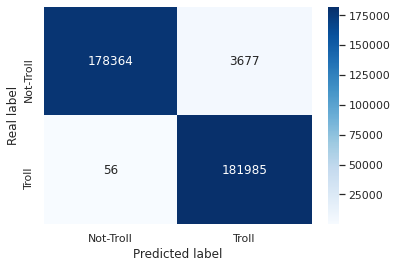

In [ ]:
class_labels = ["Not-Troll", "Troll"]
print("Accuracy:",accuracy_score(y_train, y_train_pred))
cm =  confusion_matrix(y_pred=y_train_pred, y_true=y_train, labels=[0,1])
plot_confusion_matrix(cm, class_labels)

In [ ]:
pd.Series(y_train).value_counts()

Accuracy: 0.9747545582047685


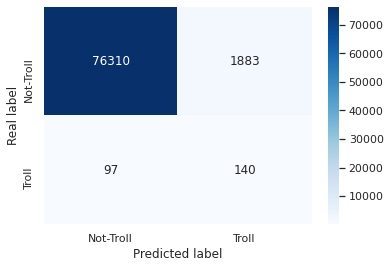

In [ ]:
X_test = vectorizer.transform(corpus_test)
y_pred = model.predict(X_test)
print("Accuracy:",accuracy_score(y_test, y_pred))
cm =  confusion_matrix(y_pred=y_pred, y_true=y_test, labels=[0,1])
plot_confusion_matrix(cm, class_labels)

In [ ]:
cm  # test set: rows = true class, columns = predicted (Not-Troll, Troll)

array([[76310,  1883],
       [   97,   140]])

**How good is this?** Of the 2,023 test tweets flagged as trolls, only 140 are trolls, so precision is **6.9%** (93% false discoveries). The model catches 140 of 237 trolls (recall 59%). Its 97.5% accuracy is *below* the 99.7% scored by always predicting "not troll". On their own, the words of a tweet don't separate trolls from other users discussing the same political topics.

## Cross-validated pipeline (revised, not re-run)

The original grid search put SMOTE on the full sparse TF-IDF matrix. It was too slow on Colab and was interrupted, which is the only output kept below. The cell has been rewritten so that:

* the TF-IDF vectoriser sits **inside** the pipeline, so it is re-fitted on each CV fold and nothing leaks from the validation folds;
* the imbalance is handled with `class_weight='balanced'`, which is much cheaper than SMOTE on high-dimensional text;
* models are selected by **F1** (accuracy is misleading with 1 troll per ~40 tweets) and evaluated on a held-out test set.

*This version has not been run, because the data is not in this repository.*

In [ ]:
t_sample = pd.read_csv(f'{DATA_DIR}/text_sample.csv')

In [ ]:
corpus = t_sample.clean_tweet_text[t_sample.lang == 'es'].apply(preprocess)
y = t_sample[t_sample.lang == 'es'].is_troll

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

class_labels = ['Not-Troll', 'Troll']
X_train_txt, X_test_txt, y_train, y_test = train_test_split(corpus, y, test_size=0.3, stratify=y, random_state=42)

text_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words=sorted(my_stopwords), use_idf=True, norm='l2')),
    ('lr', LogisticRegression(class_weight='balanced', max_iter=1000)),
])
param_grid = {
    'tfidf__min_df': [5, 10, 20],
    'tfidf__max_df': [0.8],
    'lr__C': [0.1, 1, 10],
}
text_gs = GridSearchCV(text_pipe, param_grid=param_grid, cv=5, scoring='f1', verbose=1, n_jobs=-1)
text_gs.fit(X_train_txt, y_train)
print('best parameters:', text_gs.best_params_)

model_results(text_gs, X_test_txt, y_test, text_gs.predict(X_test_txt), class_labels)

KeyboardInterrupt: ignored

# Account + tweet-statistics model (no text)

`a_sample.csv` (account features only) and `ts_sample.csv` (tweet statistics only) were built above but not modelled separately. The model below uses both groups of features together (`at_sample.csv`).

Categorical features (`lang`, `tweet_client_name`) are target-encoded, all features are standardised, the training set is balanced with SMOTE, and a logistic regression is fitted.

In [ ]:
at_sample = pd.read_csv(f'{DATA_DIR}/at_sample.csv')
np.random.seed(42)  # added later; the saved outputs come from an unseeded run
msk = np.random.rand(len(at_sample)) < 0.7
at_sample_train = at_sample[msk]
at_sample_test = at_sample[~msk]
cols = ['tweet_len', 'abbr_count', 'stopwords_count', 'hashtag_count',
       'mention_count', 'caps_to_normal', 'lang', 'follower_count',
       'following_count', 'tweet_client_name', 'like_count', 'retweet_count',
       'is_com_or_rt', 'num_in_name', 'follower_to_following']
       

In [ ]:
X_train = at_sample_train.dropna()[cols]
X_test = at_sample_test.dropna()[cols]
y_train = at_sample_train.dropna().is_troll
y_test = at_sample_test.dropna().is_troll

In [ ]:
!pip install category_encoders

     |████████████████████████████████| 81kB 3.7MB/s 


In [ ]:
from category_encoders import TargetEncoder
cat_cols_names = ['lang', 'tweet_client_name']
encoder = TargetEncoder()
X_train[cat_cols_names] = encoder.fit_transform(X_train[cat_cols_names], y_train)

/usr/local/lib/python3.7/dist-packages/category_encoders/utils.py:21: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  elif pd.api.types.is_categorical(cols):


In [ ]:
X_test[cat_cols_names] = encoder.transform(X_test[cat_cols_names])

In [ ]:
from sklearn.preprocessing import StandardScaler
# define standard scaler
scaler = StandardScaler()
# transform data
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)  # known issue: should be scaler.transform(X_test); kept so the results below match
oversample = SMOTE()
X_train, y_train  = oversample.fit_resample(X_train, y_train )
model = LogisticRegression().fit(X_train, y_train)
y_train_pred = model.predict(X_train)

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function safe_indexing is deprecated; safe_indexing is deprecated in version 0.22 and will be removed in version 0.24.
  warnings.warn(msg, category=FutureWarning)
/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_logistic.py:940: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  extra_warning_msg=_LOGISTIC_SOLVER_CONVERGENCE_MSG)


Accuracy: 0.9913876403671874


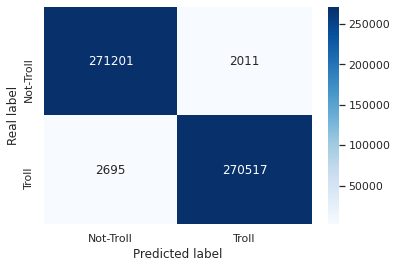

In [ ]:
class_labels = ["Not-Troll", "Troll"]
print("Accuracy:",accuracy_score(y_train, y_train_pred))
cm =  confusion_matrix(y_pred=y_train_pred, y_true=y_train, labels=[0,1])
plot_confusion_matrix(cm, class_labels)

Accuracy: 0.9914926786747018


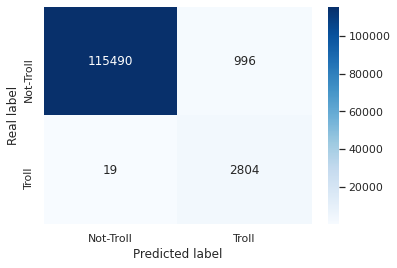

In [ ]:
y_pred = model.predict(X_test)
print("Accuracy:",accuracy_score(y_test, y_pred))
cm =  confusion_matrix(y_pred=y_pred, y_true=y_test, labels=[0,1])
plot_confusion_matrix(cm, class_labels)

On the test set: 2,804 of 2,823 trolls are caught (**recall 99.3%**), and 74% of the flagged tweets are trolls (**precision 73.8%**). Accuracy is 99.1%, compared with 97.6% for always predicting "not troll". The client app, posting time and digits in the display name do most of the work. As noted at the top, some of these signals may partly reflect how the two datasets were collected.

# Conclusions and next steps

* **Behaviour beats wording.** Account metadata and posting behaviour identify troll tweets far better than the text. The troll tweets use the same political vocabulary as ordinary users discussing the same topics.
* **Accuracy is misleading here.** With about 1 troll per 40 tweets, precision, recall and F1 (or PR-AUC) should drive model selection.

Next steps:

1. Re-run the cleaning with `remove_abbr(..., whole_words=True)` and fix the scaler and `hashtag_count` issues listed at the top.
2. Evaluate the account-only and tweet-statistics-only feature sets separately to see which signals matter most, and drop features that may reflect data collection (e.g. client app) to test robustness.
3. Split train and test **by account** rather than by tweet, so the model cannot memorise individual accounts.
4. Try multilingual text representations (e.g. multilingual BERT) for the Catalan and Spanish text instead of language-specific TF-IDF.